# **Loading the Files**


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
BASE_PATH = "/content/drive/MyDrive/Projects/Tennis/v1/datasets"


In [3]:
import pandas as pd

train = pd.read_parquet(f"{BASE_PATH}/v1_train.parquet")
val = pd.read_parquet(f"{BASE_PATH}/v1_val.parquet")
test = pd.read_parquet(f"{BASE_PATH}/v1_test.parquet")

train_log = pd.read_parquet(f"{BASE_PATH}/v1_train_log.parquet")
val_log = pd.read_parquet(f"{BASE_PATH}/v1_val_log.parquet")
test_log = pd.read_parquet(f"{BASE_PATH}/v1_test_log.parquet")


In [4]:
# #test-1
# for name, df in {
#     "train": train,
#     "val": val,
#     "test": test,
#     "train_log": train_log,
#     "val_log": val_log,
#     "test_log": test_log,
# }.items():
#     print(name, df.shape)


# **Seperating Predictors and Labels**


In [43]:
import gc
target_cols = ['playerA_match_p', 'playerB_match_p']

X_train_log = train_log.drop(columns= target_cols + ['playerA_wins'], axis= 1)
y_trainA_log = train_log[target_cols[0]]
y_trainB_log = train_log[target_cols[1]]

X_val_log = val_log.drop(columns= target_cols + ['playerA_wins'], axis= 1)
y_valA_log = val_log[target_cols[0]]
y_valB_log = val_log[target_cols[1]]

del train_log
del val_log
gc.collect()


237

In [6]:
import gc
target_cols = ['playerA_match_p', 'playerB_match_p']

X_train = train.drop(columns= target_cols + ['playerA_wins'], axis= 1)
y_trainA = train[target_cols[0]]
y_trainB = train[target_cols[1]]

X_val = val.drop(columns= target_cols + ['playerA_wins'], axis= 1)
y_valA = val[target_cols[0]]
y_valB = val[target_cols[1]]

del val
del train
gc.collect()


0

In [7]:
import gc
target_cols = ['playerA_match_p', 'playerB_match_p']

test_winner = test['playerA_wins']
X_test = test.drop(columns= target_cols + ['playerA_wins'], axis = 1)
y_testA = test[target_cols[0]]
y_testB = test[target_cols[1]]

X_test_log = test_log.drop(columns= target_cols + ['playerA_wins'], axis= 1)

del test
del test_log
gc.collect()


0

# **Training Models**


## Importing Libraries

In [6]:
!git clone https://github.com/rapidsai/rapidsai-csp-utils.git

Cloning into 'rapidsai-csp-utils'...
remote: Enumerating objects: 700, done.
remote: Counting objects: 100% (216/216), done.
remote: Compressing objects: 100% (77/77), done.
remote: Total 700 (delta 186), reused 139 (delta 139), pack-reused 484 (from 1)
Receiving objects: 100% (700/700), 234.66 KiB | 6.17 MiB/s, done.
Resolving deltas: 100% (370/370), done.


In [7]:
!python rapidsai-csp-utils/colab/pip-install.py

Installing RAPIDS remaining 26.02 libraries
Using Python 3.12.13 environment at: /usr
Resolved 180 packages in 2.01s
Prepared 10 packages in 1.28s
Uninstalled 4 packages in 220ms
Installed 10 packages in 42ms
 - bokeh==3.8.2
 + bokeh==3.6.3
 + cugraph-cu12==26.2.0
 + cuxfilter-cu12==26.2.0
 + datashader==0.19.1
 - holoviews==1.23.0
 + holoviews==1.20.2
 + jupyter-server-proxy==4.5.0
 - panel==1.9.3
 + panel==1.7.5
 + pyct==0.6.0
 - shapely==2.1.2
 + shapely==2.0.7
 + simpervisor==1.0.0

        ***********************************************************************
        The pip install of RAPIDS is complete.

        Please do not run any further installation from the conda based installation methods, as they may cause issues!

        Please ensure that you're pulling from the git repo to remain updated with the latest working install scripts.

        Troubleshooting:
            - If there is an installation failure, please check back on RAPIDSAI owned templates/notebooks to see 

In [8]:
import cuml
print(cuml.__version__)

26.02.000


## Ridge Regression


### Base Model (Scaled)


In [6]:
from sklearn.preprocessing import StandardScaler

def scaling(dataset):
    scaler = StandardScaler()

    dataset_scaled = scaler.fit_transform(dataset)
    return dataset_scaled


In [7]:
from sklearn.linear_model import Ridge
import joblib
from google.colab import drive
import time

start_time = time.time()
ridge = Ridge(alpha= 1.0, fit_intercept= True, solver= 'auto', random_state= 42)

#for predicting playerA's serve pct
ridge.fit(scaling(X_train_log), y_trainA_log)
elapsed_time = time.time() - start_time

#saving the model
drive.mount('/content/drive')
MODEL_PATH = "/content/drive/MyDrive/Projects/Tennis/v1/models/raw_models/ridge_base_playerA.pkl"
joblib.dump(ridge, MODEL_PATH)
print("Model saved.")
print("Elapsed Time: ", f"{elapsed_time:.3f}", " seconds")


/usr/local/lib/python3.12/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=1.26391e-08): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model saved.
Elapsed Time:  0.948  seconds


In [8]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
val_preds = ridge.predict(scaling(X_val_log))
val_preds = np.clip(val_preds, 0, 1)


#evaluation
mae = mean_absolute_error(y_valA_log, val_preds)
rmse = np.sqrt(mean_squared_error(y_valA_log, val_preds))
r2 = r2_score(y_valA_log, val_preds)

print(f"MAE : {mae:.6f}")
print(f"RMSE: {rmse:.6f}")
print(f"R²  : {r2:.6f}")


MAE : 0.065217
RMSE: 0.083777
R²  : 0.225001


### Hyperparameter Search


In [42]:
import time  #4000s
import numpy as np
import pandas as pd

from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from cuml.linear_model import Ridge
from cuml.preprocessing import StandardScaler

X_train_gpu = X_train_log.astype(np.float32)
y_trainA_gpu = y_trainA.astype(np.float32)

param_grid = {
    "alpha": np.logspace(-4, 4, 50).astype(np.float32),
    "solver": ["auto", "eig", "svd"],  
    # "tol": [1e-3, 1e-4, 1e-5]
}
tscv = TimeSeriesSplit(n_splits= 3)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_gpu)

start_time = time.time()

ridge = Ridge(alpha=1.0, fit_intercept=True, solver='eig', output_type='numpy')
rscv = RandomizedSearchCV(estimator= ridge, param_distributions= param_grid, random_state = 42, n_iter = 20, 
                          scoring = "neg_mean_absolute_error", cv = tscv)
search = rscv.fit(X_train_scaled, y_trainA_gpu)

elapsed_time = time.time() - start_time
print(f"Elapsed Time: {elapsed_time/60:.4f} minutes.")


Elapsed Time: 0.1451 minutes.


In [43]:
print("Best parameters for Ridge:", search.best_params_)

Best parameters for Ridge: {'solver': 'auto', 'alpha': np.float32(1526.418)}


In [44]:
search.best_score_

np.float64(-0.06489502390225728)

In [45]:
search.cv_results_

{'mean_fit_time': array([0.10202297, 0.09844653, 0.09779215, 0.10206596, 0.09876593,
        0.10009766, 0.1191318 , 0.1305867 , 0.21114802, 0.12758168,
        0.21153029, 0.12324548, 0.12343582, 0.12636876, 0.11561839,
        0.18071294, 0.17255489, 0.10460416, 0.09862137, 0.09749881]),
 'std_fit_time': array([0.03406581, 0.03148663, 0.02963651, 0.03380294, 0.03095234,
        0.03077662, 0.05508204, 0.03991815, 0.05696074, 0.04399063,
        0.07021336, 0.03574723, 0.03867153, 0.03902755, 0.02702268,
        0.06567462, 0.05863881, 0.03746188, 0.02950137, 0.02981559]),
 'mean_score_time': array([0.01478823, 0.01457294, 0.01513545, 0.0145402 , 0.01453582,
        0.0146629 , 0.01677497, 0.01573571, 0.01795435, 0.01574461,
        0.01741878, 0.01533492, 0.01603055, 0.01619784, 0.0165596 ,
        0.01635957, 0.01648998, 0.01468547, 0.01453098, 0.01479379]),
 'std_score_time': array([2.70895154e-04, 2.06811806e-04, 8.83415325e-04, 5.67910186e-05,
        1.71027108e-04, 3.04426720e-

### Best Model


In [46]:
from sklearn.preprocessing import StandardScaler

def scaling(dataset):
    scaler = StandardScaler()

    dataset_scaled = scaler.fit_transform(dataset)
    return dataset_scaled


In [47]:
import joblib
import time
from google.colab import drive

from cuml.linear_model import Ridge as cumlRidge
from cuml.preprocessing import StandardScaler
from sklearn.linear_model import Ridge as sklearnRidge

#Data Conversion
X_train_gpu = X_train_log.astype(np.float32)
y_trainB_gpu = y_trainB.astype(np.float32)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_gpu)


start_time = time.time()

#Player A
ridge_A = search.best_estimator_.as_sklearn()


#Player B
ridge_B_gpu = cumlRidge(alpha= search.best_params_['alpha'], fit_intercept= True, solver= search.best_params_['solver'])
ridge_B_gpu.fit(X_train_scaled, y_trainB_gpu)
ridge_B = ridge_B_gpu.as_sklearn()

elapsed_time = time.time() - start_time
print(f"Elapsed Time: {elapsed_time:.4f} seconds")


#saving the models
drive.mount('/content/drive')
MODEL_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1/models/stage1_models/ridge_stage1_scaled_playerA.pkl"
MODEL_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1/models/stage1_models/ridge_stage1_scaled_playerB.pkl"
joblib.dump(ridge_A, MODEL_PATH_A)
joblib.dump(ridge_B, MODEL_PATH_B)
print("Models saved.")


Elapsed Time: 0.0745 seconds
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Models saved.


In [48]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
val_preds_A = ridge_A.predict(scaling(X_val_log))
val_preds_A = np.clip(val_preds_A, 0, 1)

val_preds_B = ridge_B.predict(scaling(X_val_log))
val_preds_B = np.clip(val_preds_B, 0, 1)


#evaluation
mae_A = mean_absolute_error(y_valA_log, val_preds_A)
rmse_A = np.sqrt(mean_squared_error(y_valA_log, val_preds_A))
r2_A = r2_score(y_valA_log, val_preds_A)

print(f"MAE (A) : {mae_A:.6f}")
print(f"RMSE (A) : {rmse_A:.6f}")
print(f"R² (A) : {r2_A:.6f}")


mae_B = mean_absolute_error(y_valB_log, val_preds_B)
rmse_B = np.sqrt(mean_squared_error(y_valB_log, val_preds_B))
r2_B = r2_score(y_valB_log, val_preds_B)

print(f"MAE (B) : {mae_B:.6f}")
print(f"RMSE (B) : {rmse_B:.6f}")
print(f"R² (B) : {r2_B:.6f}")


MAE (A) : 0.065235
RMSE (A) : 0.083792
R² (A) : 0.224713
MAE (B) : 0.064640
RMSE (B) : 0.083147
R² (B) : 0.233166


## Elastic Net Regression


In [23]:
from sklearn.preprocessing import StandardScaler

def scaling(dataset):
    scaler = StandardScaler()

    dataset_scaled = scaler.fit_transform(dataset)
    return dataset_scaled


### Base Model


In [24]:
from sklearn.linear_model import ElasticNet
import joblib
from google.colab import drive
import time

start_time = time.time()
enet = ElasticNet(alpha= 1.0, fit_intercept= True, random_state= 42, l1_ratio= 0.5, max_iter= 10000, tol = 1e-4,
                   selection= 'cyclic', positive= False)

#for predicting playerA's serve pct
enet.fit(scaling(X_train_log), y_trainA_log)
elapsed_time = time.time() - start_time

#saving the model
drive.mount('/content/drive')
MODEL_PATH = "/content/drive/MyDrive/Projects/Tennis/v1/models/raw_models/enet_base_scaled_playerA.pkl"
joblib.dump(enet, MODEL_PATH)
print("Model saved.")
print(f"Elapsed Time: {elapsed_time} seconds")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model saved.
Elapsed Time: 0.835115909576416 seconds


In [25]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
val_preds = enet.predict(scaling(X_val_log))
val_preds = np.clip(val_preds, 0, 1)


#evaluation
mae = mean_absolute_error(y_valA_log, val_preds)
rmse = np.sqrt(mean_squared_error(y_valA_log, val_preds))
r2 = r2_score(y_valA_log, val_preds)

print(f"MAE : {mae:.6f}")
print(f"RMSE: {rmse:.6f}")
print(f"R²  : {r2:.6f}")


MAE : 0.074905
RMSE: 0.095194
R²  : -0.000630


### Hyperparameter Tuning


In [36]:
import numpy as np #400s
import time
import pandas as pd

from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from cuml.linear_model import ElasticNet

X_train_gpu = X_train_log.astype(np.float32)
y_trainA_gpu = y_trainA.astype(np.float32)

param_grid = {
    "alpha": np.logspace(-5, 1, 50),
    "l1_ratio": [0.05, 0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90, 0.95]
}

tscv = TimeSeriesSplit(n_splits=3)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_gpu)

start_time = time.time()
enet = ElasticNet(alpha= 1.0, fit_intercept= True, l1_ratio= 0.5, max_iter= 10000, tol = 1e-4, selection= 'cyclic')
rscv = RandomizedSearchCV(estimator= enet, param_distributions= param_grid, random_state = 42, n_iter = 20, 
                          scoring = "neg_mean_absolute_error", cv = tscv)
search = rscv.fit(X_train_scaled, y_trainA_gpu)


elapsed_time = time.time() - start_time
print(f"Elapsed Time: {elapsed_time/60:.4f} minutes.")


Elapsed Time: 4.7836 minutes.


In [37]:
print("Best parameters for ElasticNet:", search.best_params_)


Best parameters for ElasticNet: {'l1_ratio': 0.05, 'alpha': np.float64(0.002811768697974231)}


In [38]:
search.best_score_

np.float64(-0.06487968812386195)

In [39]:
search.cv_results_

{'mean_fit_time': array([ 1.76722225, 10.35307733,  0.11509736,  3.58610352,  0.11492856,
         0.119145  ,  4.96323077,  0.11411595, 11.08605353,  0.53515855,
         1.50202847, 16.07620064,  5.92163928,  3.12213429,  1.58298111,
         5.55711365,  0.1130422 , 25.54287926,  1.9725643 ,  0.11742258]),
 'std_fit_time': array([1.2908371 , 1.14443977, 0.03068056, 1.75634703, 0.03339192,
        0.03170213, 0.86890087, 0.03114139, 0.62248523, 0.02667852,
        0.50295832, 2.5212038 , 1.02337032, 0.44341563, 0.79942137,
        1.33080318, 0.03256007, 3.63821496, 1.16780526, 0.03630055]),
 'mean_score_time': array([0.01472839, 0.01497277, 0.01472608, 0.01559742, 0.01438347,
        0.01420609, 0.01482876, 0.01433086, 0.01513124, 0.01466751,
        0.01466894, 0.01527405, 0.01519505, 0.01505693, 0.01514546,
        0.01471432, 0.01404715, 0.01526252, 0.01469938, 0.01433579]),
 'std_score_time': array([5.93096533e-05, 3.66660818e-04, 7.51354514e-04, 1.32991434e-03,
        1.631429

### Best Model


In [40]:
from sklearn.linear_model import ElasticNet as sklearnElasticNet
from cuml.linear_model import ElasticNet as cumlElasticNet
import joblib
from google.colab import drive
import time

#Data Conversion
X_train_gpu = X_train_log.astype(np.float32)
y_trainB_gpu = y_trainB.astype(np.float32)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_gpu)

start_time = time.time()

#Player A
enet_A = search.best_estimator_.as_sklearn()

#Player B
enet_B_gpu = cumlElasticNet(alpha= search.best_params_['alpha'], l1_ratio= search.best_params_['l1_ratio'], fit_intercept= True,
                            max_iter= 10000, tol = 1e-4, selection= 'cyclic')
enet_B_gpu.fit(X_train_scaled, y_trainB_gpu)
enet_B = enet_B_gpu.as_sklearn()

elapsed_time = time.time() - start_time
print(f"Elapsed Time: {elapsed_time:.4f} seconds")

#saving the model
drive.mount('/content/drive')
MODEL_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1/models/stage1_models/enet_stage1_scaled_playerA.pkl"
joblib.dump(enet_A, MODEL_PATH_A)
MODEL_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1/models/stage1_models/enet_stage1_scaled_playerB.pkl"
joblib.dump(enet_B, MODEL_PATH_B)
print("Models saved.")


Elapsed Time: 4.1555 seconds
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Models saved.


In [41]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
val_preds_A = enet_A.predict(scaling(X_val_log))
val_preds_A = np.clip(val_preds_A, 0, 1)

val_preds_B = enet_B.predict(scaling(X_val_log))
val_preds_B = np.clip(val_preds_B, 0, 1)


#evaluation
mae_A = mean_absolute_error(y_valA_log, val_preds_A)
rmse_A = np.sqrt(mean_squared_error(y_valA_log, val_preds_A))
r2_A = r2_score(y_valA_log, val_preds_A)

mae_B = mean_absolute_error(y_valB_log, val_preds_B)
rmse_B = np.sqrt(mean_squared_error(y_valB_log, val_preds_B))
r2_B = r2_score(y_valB_log, val_preds_B)

print(f"MAE (A) : {mae_A:.6f}")
print(f"RMSE (A): {rmse_A:.6f}")
print(f"R² (A) : {r2_A:.6f}")

print(f"MAE (B) : {mae_B:.6f}")
print(f"RMSE (B): {rmse_B:.6f}")
print(f"R² (B) : {r2_B:.6f}")


MAE (A) : 0.065244
RMSE (A): 0.083807
R² (A) : 0.224447
MAE (B) : 0.064649
RMSE (B): 0.083168
R² (B) : 0.232784


## Random Forest


### Base Model


In [12]:
import joblib #1300 s
from google.colab import drive
import time
from cuml.ensemble import RandomForestRegressor as cumlRandomForestRegressor
from sklearn.ensemble import RandomForestRegressor
import cudf

#Data Conversion
X_train_gpu = cudf.from_pandas(X_train)
y_trainA_gpu = cudf.from_pandas(y_trainA)

start_time = time.time()
rfreg= cumlRandomForestRegressor(n_estimators = 500, max_features= "sqrt", random_state = 42, output_type= 'numpy')
rfreg.fit(X_train_gpu, y_trainA_gpu)
elapsed_time = time.time() - start_time

rfreg_sk = rfreg.as_sklearn()

#saving the model
drive.mount('/content/drive')
MODEL_PATH = "/content/drive/MyDrive/Projects/Tennis/v1/models/raw_models/randomForest_base_playerA.pkl"
joblib.dump(rfreg_sk, MODEL_PATH)
print("Model saved.")
print(f"Elasped Time: {elapsed_time/60:.4f} minutes")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model saved.
Elasped Time: 0.3195 minutes


In [13]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import gc
val_preds = rfreg_sk.predict(X_val)
val_preds = np.clip(val_preds, 0, 1)


#evaluation
mae = mean_absolute_error(y_valA, val_preds)
rmse = np.sqrt(mean_squared_error(y_valA, val_preds))
r2 = r2_score(y_valA, val_preds)

print(f"MAE : {mae:.6f}")
print(f"RMSE: {rmse:.6f}")
print(f"R²  : {r2:.6f}")

del rfreg_sk
del rfreg
del val_preds
gc.collect()

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but RandomForestRegressor was fitted without feature names
  warnings.warn(


MAE : 0.065510
RMSE: 0.084057
R²  : 0.219805


25

### Hyperparameter Search


In [6]:
from sklearn.ensemble import RandomForestRegressor #3442s
from sklearn.model_selection import TimeSeriesSplit
from sklearn.model_selection import RandomizedSearchCV
import joblib
import time

tscv = TimeSeriesSplit(n_splits = 3)
param_grid = {
    "n_estimators": [300, 500],
    "max_features": ["sqrt", "log2", 0.25, 0.5, 0.75],
    "max_depth": [None, 10, 20, 40],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 5]
}

start_time = time.time()
rfreg = RandomForestRegressor(n_estimators= 500, random_state= 42, n_jobs= -1)
rscv = RandomizedSearchCV(rfreg, param_distributions= param_grid, n_iter= 15, cv = tscv, n_jobs= -1)
search = rscv.fit(X_train, y_trainA)

elapsed_time = time.time() - start_time
print(f"Elapsed Time: {elapsed_time/60:.4f} minutes.")

/usr/local/lib/python3.12/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Elapsed Time: 354.9937 minutes.


In [7]:
print("Best parameters for RandomForest:", search.best_params_)

Best parameters for RandomForest: {'n_estimators': 500, 'min_samples_split': 5, 'min_samples_leaf': 5, 'max_features': 0.5, 'max_depth': None}


In [8]:
search.best_score_

np.float64(0.25050466010297195)

In [9]:
search.cv_results_

{'mean_fit_time': array([7053.33504041, 1257.8459727 , 6074.08722305, 3847.09911243,
        6535.85617089,  509.27568857,  700.90560389, 2386.6972038 ,
        7792.75260647,  302.09448727,  818.7132837 , 3769.4118766 ,
        1214.92269516, 3956.00728257,  864.29403853]),
 'std_fit_time': array([3309.04601596,  551.71675064, 2664.63493837, 1807.82972952,
        2858.74954513,  220.68581701,  325.4978869 , 1083.91784212,
        2370.13501212,  143.99506539,  375.51699304, 1598.76421995,
         558.03766727,  844.97320955,  365.96959159]),
 'mean_score_time': array([14.54323872,  4.01974837,  5.86595551, 15.7654736 ,  9.11058656,
         6.3112731 , 11.37955554,  9.73165766,  7.45719433, 10.74297762,
        13.39285692,  7.49492478, 23.10441812,  3.45079438, 13.4900887 ]),
 'std_score_time': array([2.0035224 , 0.10879019, 0.61410516, 2.0010151 , 1.4063409 ,
        0.3871292 , 2.01394741, 0.98814552, 4.31832374, 1.29408533,
        1.35338073, 1.36736318, 3.62857699, 1.23812142,

### Best Model


In [11]:
from sklearn.ensemble import RandomForestRegressor
import joblib
import time
from google.colab import drive



#PlayerA
rfr_A = search.best_estimator_

#PlayerB
rfr_B= RandomForestRegressor(n_estimators= search.best_params_['n_estimators'], random_state= 42, 
                                      max_features = search.best_params_['max_features'], max_depth= search.best_params_['max_depth'],
                                      min_samples_split= search.best_params_['min_samples_split'], n_jobs= -1,
                                      min_samples_leaf = search.best_params_['min_samples_leaf'])
rfr_B.fit(X_train, y_trainB)

elapsed_time = time.time() - start_time
print(f"Elapsed Time: {elapsed_time:.4f} seconds")

#saving the models
drive.mount('/content/drive')
MODEL_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1/models/stage1_models/randomForest_stage1_playerA.pkl"
MODEL_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1/models/stage1_models/randomForest_stage1_playerB.pkl"
joblib.dump(rfr_A, MODEL_PATH_A)
joblib.dump(rfr_B, MODEL_PATH_B)
print("Models saved.")


Elapsed Time: 23404.9649 seconds
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Models saved.


In [12]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import gc
val_preds_A = rfr_A.predict(X_val)
val_preds_A = np.clip(val_preds_A, 0, 1)

val_preds_B = rfr_B.predict(X_val)
val_preds_B = np.clip(val_preds_B, 0, 1)


#evaluation
mae_A = mean_absolute_error(y_valA, val_preds_A)
rmse_A = np.sqrt(mean_squared_error(y_valA, val_preds_A))
r2_A = r2_score(y_valA, val_preds_A)

print(f"MAE (A) : {mae_A:.6f}")
print(f"RMSE (A) : {rmse_A:.6f}")
print(f"R² (A) : {r2_A:.6f}")


mae_B = mean_absolute_error(y_valB, val_preds_B)
rmse_B = np.sqrt(mean_squared_error(y_valB, val_preds_B))
r2_B = r2_score(y_valB, val_preds_B)

print(f"MAE (B) : {mae_B:.6f}")
print(f"RMSE (B) : {rmse_B:.6f}")
print(f"R² (B) : {r2_B:.6f}")

del rfr_A
del rfr_B
del val_preds_A
del val_preds_B
gc.collect()


MAE (A) : 0.065311
RMSE (A) : 0.083854
R² (A) : 0.223560
MAE (B) : 0.064632
RMSE (B) : 0.083097
R² (B) : 0.234089


50

## ExtraTrees Regression


### Base Model


In [14]:
import joblib #550s
from google.colab import drive 
import time 
from sklearn.ensemble import ExtraTreesRegressor


start_time = time.time()
etreg = ExtraTreesRegressor(n_estimators= 200, max_features= 'sqrt', random_state= 42)
etreg.fit(X_train, y_trainA)
elapsed_time = time.time() - start_time

print(f"Elapsed Time: {elapsed_time/60:.4f} minutes")

#saving the model
drive.mount('/content/drive')
MODEL_PATH = "/content/drive/MyDrive/Projects/Tennis/v1/models/raw_models/extraTrees_base_playerA.pkl"
joblib.dump(etreg, MODEL_PATH)
print("Model saved.")


Elapsed Time: 5.9794 minutes
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model saved.


In [15]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import gc
val_preds = etreg.predict(X_val)
val_preds = np.clip(val_preds, 0, 1)


#evaluation
mae = mean_absolute_error(y_valA, val_preds)
rmse = np.sqrt(mean_squared_error(y_valA, val_preds))
r2 = r2_score(y_valA, val_preds)

print(f"MAE : {mae:.6f}")
print(f"RMSE: {rmse:.6f}")
print(f"R²  : {r2:.6f}")

del etreg
del val_preds
gc.collect()

MAE : 0.066146
RMSE: 0.084806
R²  : 0.205844


46

### Hyperparameter Tuning


In [16]:
#7404s
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
import time 

tscv = TimeSeriesSplit(n_splits = 3)
param_grid = {
    "n_estimators": [300, 500, 1000],
    "max_features": ["sqrt", "log2", 0.25, 0.5, 0.75],
    "max_depth": [None, 10, 20, 40],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 5],
    "bootstrap": [True, False]
}

start_time = time.time()
etreg = ExtraTreesRegressor(n_estimators= 200, max_features= 'sqrt', random_state= 42, n_jobs= -1)
rscv = RandomizedSearchCV(etreg, param_distributions= param_grid, n_iter= 10, cv = tscv, n_jobs= -1)
search = rscv.fit(X_train, y_trainA)

elapsed_time = time.time() - start_time
print(f"Elapsed Time: {elapsed_time/60:.4f} minutes.")


/usr/local/lib/python3.12/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Elapsed Time: 105.3214 minutes.


In [ ]:
print("Best parameters for ExtraTrees:", search.best_params_)

Best parameters for ExtraTrees: {'n_estimators': 1000, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 0.75, 'max_depth': None, 'bootstrap': True}


In [ ]:
search.best_score_

np.float64(0.24603873200477058)

In [ ]:
search.cv_results_

{'mean_fit_time': array([ 307.56567208, 2877.41758362,   39.47672184,  125.12918234,
         900.71171665,  489.07712086, 1278.96975215,  116.88179882,
         250.13144064, 2419.86616532]),
 'std_fit_time': array([137.6910155 , 932.00486585,  18.76010535,  59.42870154,
        430.40929526, 237.25222755, 567.11455672,  47.9489298 ,
        124.38465679, 465.32629587]),
 'mean_score_time': array([ 3.80186844, 26.56058526,  3.51226544, 13.66206415, 15.81642493,
        47.36294357, 10.01308386, 13.20156519, 22.00362364, 12.00019646]),
 'std_score_time': array([0.51352554, 7.34853239, 0.26094047, 1.08606005, 3.22250446,
        5.77012621, 0.72821723, 2.39343778, 3.78788672, 5.38272591]),
 'param_n_estimators': masked_array(data=[300, 1000, 300, 500, 300, 1000, 300, 300, 500, 1000],
              mask=[False, False, False, False, False, False, False, False,
                    False, False],
        fill_value=999999),
 'param_min_samples_split': masked_array(data=[2, 2, 2, 2, 2, 5, 5,

### Best Model


In [21]:
from sklearn.ensemble import ExtraTreesRegressor #2508
import joblib
from google.colab import drive
import time 

#Player A
etreg_A = search.best_estimator_


#saving the model
drive.mount('/content/drive')
MODEL_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1/models/stage1_models/extraTrees_stage1_playerA.pkl"
joblib.dump(etreg_A, MODEL_PATH_A)
print("Model saved.")
print(elapsed_time)    

#evaluation
val_preds_A = etreg_A.predict(X_val)
val_preds_A = np.clip(val_preds_A, 0, 1)

mae_A = mean_absolute_error(y_valA, val_preds_A)
rmse_A = np.sqrt(mean_squared_error(y_valA, val_preds_A))
r2_A = r2_score(y_valA, val_preds_A)

print(f"MAE (A) : {mae_A:.6f}")
print(f"RMSE (A) : {rmse_A:.6f}")
print(f"R² (A) : {r2_A:.6f}")

del etreg_A
del val_preds_A
del mae_A, rmse_A, r2_A
gc.collect()


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model saved.
6319.285305976868
MAE (A) : 0.065387
RMSE (A) : 0.083937
R² (A) : 0.222026


316

In [22]:
#PlayerB 2506s
start_time = time.time()
etreg_B = ExtraTreesRegressor(n_estimators= search.best_params_['n_estimators'], random_state= 42, n_jobs= -1,
                                       max_features = search.best_params_['max_features'], max_depth= search.best_params_['max_depth'],
                                       min_samples_split= search.best_params_['min_samples_split'], 
                                       min_samples_leaf = search.best_params_['min_samples_leaf'], 
                                       bootstrap= search.best_params_['bootstrap'])
etreg_B.fit(X_train, y_trainB)

elapsed_time = time.time() - start_time
print(f"Elapsed Time: {elapsed_time:.4f} seconds")

drive.mount('/content/drive')
MODEL_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1/models/stage1_models/extraTrees_stage1_playerB.pkl"

joblib.dump(etreg_B, MODEL_PATH_B)
print("Model saved.")
print(elapsed_time)

val_preds_B = etreg_B.predict(X_val)
val_preds_B = np.clip(val_preds_B, 0, 1)


#evaluation
mae_B = mean_absolute_error(y_valB, val_preds_B)
rmse_B = np.sqrt(mean_squared_error(y_valB, val_preds_B))
r2_B = r2_score(y_valB, val_preds_B)

print(f"MAE (B) : {mae_B:.6f}")
print(f"RMSE (B) : {rmse_B:.6f}")
print(f"R² (B) : {r2_B:.6f}")

del etreg_B
del val_preds_B
del mae_B, rmse_B, r2_B
gc.collect()


Elapsed Time: 1567.6377 seconds
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model saved.
1567.6376504898071
MAE (B) : 0.064716
RMSE (B) : 0.083195
R² (B) : 0.232279


25

## XGBoost Regressor


### Base Model


In [32]:
from xgboost import XGBRegressor #103s
import joblib
from google.colab import drive
import time

start_time =time.time()
xgb = XGBRegressor(objective="reg:squarederror", n_estimators=500, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8,
    random_state=42, tree_method="hist", device="cuda")

#for predicting playerA's serve
xgb.fit(X_train, y_trainA)
elapsed_time = time.time() - start_time

#saving the model
drive.mount('/content/drive')
MODEL_PATH = "/content/drive/MyDrive/Projects/Tennis/v1/models/raw_models/XGBoost_base_playerA.pkl"
joblib.dump(xgb, MODEL_PATH)
print("Model saved.")
print(elapsed_time)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model saved.
9.44284701347351


In [33]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
val_preds = xgb.predict(X_val)
val_preds = np.clip(val_preds, 0, 1)


#evaluation
mae = mean_absolute_error(y_valA, val_preds)
rmse = np.sqrt(mean_squared_error(y_valA, val_preds))
r2 = r2_score(y_valA, val_preds)

print(f"MAE : {mae:.6f}")
print(f"RMSE: {rmse:.6f}")
print(f"R²  : {r2:.6f}")


MAE : 0.064769
RMSE: 0.083254
R²  : 0.234635


### Hyperparameter Search


In [8]:
from sklearn.model_selection import RandomizedSearchCV #1045s
from xgboost import XGBRegressor
from sklearn.model_selection import TimeSeriesSplit
import time 

param_grid = {
    "n_estimators": [300, 500, 1000],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "max_depth": [4, 6, 8],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0]
}


start_time = time.time()
tscv = TimeSeriesSplit(n_splits = 3)
xgb = XGBRegressor(objective="reg:squarederror", n_estimators=500, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8,
    random_state=42, tree_method="hist", device="cuda")

rscv = RandomizedSearchCV(xgb, param_distributions= param_grid, random_state= 42, n_iter= 10, scoring= "neg_mean_absolute_error", 
                          cv = tscv)
search = rscv.fit(X_train, y_trainA)
elapsed_time = time.time() - start_time

print(f"Elapsed Time: {elapsed_time:.4f} seconds.")


/usr/local/lib/python3.12/dist-packages/xgboost/core.py:553: UserWarning: [04:35:41] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


Elapsed Time: 555.4584 seconds.


In [9]:
print("Best parameters for XGBoost:", search.best_params_)

Best parameters for XGBoost: {'subsample': 0.8, 'n_estimators': 1000, 'max_depth': 6, 'learning_rate': 0.01, 'colsample_bytree': 1.0}


In [10]:
search.best_score_

np.float64(-0.06446953614552815)

In [11]:
search.cv_results_

{'mean_fit_time': array([16.67473237, 10.63182727, 25.25125559, 13.08787139, 13.55756752,
        17.26722725, 13.04179358, 24.0590481 , 15.87420487, 11.83907525]),
 'std_fit_time': array([3.97007392, 3.06512571, 3.40167429, 3.00085498, 2.77803755,
        3.57147924, 3.12898894, 4.15435896, 3.68636826, 2.61867063]),
 'mean_score_time': array([1.07746037, 1.19410801, 1.11369371, 0.91290275, 0.99552043,
        1.22937973, 1.00379602, 1.49745043, 1.15798815, 0.91816711]),
 'std_score_time': array([0.06077392, 0.37456211, 0.06847533, 0.10533234, 0.04524754,
        0.43664666, 0.04610897, 0.2852203 , 0.28211693, 0.06299386]),
 'param_subsample': masked_array(data=[1.0, 1.0, 0.8, 1.0, 0.8, 0.8, 0.8, 1.0, 0.8, 0.8],
              mask=[False, False, False, False, False, False, False, False,
                    False, False],
        fill_value=1e+20),
 'param_n_estimators': masked_array(data=[500, 300, 1000, 300, 500, 300, 300, 1000, 300, 300],
              mask=[False, False, False, Fals

### Best Model


In [12]:
from xgboost import XGBRegressor #375s
import joblib
from google.colab import drive
import time

start_time = time.time()
xgb_A = search.best_estimator_

xgb_B = XGBRegressor(objective="reg:squarederror", n_estimators=search.best_params_['n_estimators'], 
                     learning_rate=search.best_params_['learning_rate'], subsample=search.best_params_['subsample'], 
                     colsample_bytree=search.best_params_['colsample_bytree'], max_depth=search.best_params_['max_depth'], 
                     tree_method="hist", device="cuda", random_state=42)


#for predicting playerB's serve pct
xgb_B.fit(X_train, y_trainB)
elapsed_time = time.time() - start_time

#saving the models
drive.mount('/content/drive')
MODEL_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1/models/stage1_models/XGBoost_stage1_playerA.pkl"
MODEL_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1/models/stage1_models/XGBoost_stage1_playerB.pkl"
joblib.dump(xgb_A, MODEL_PATH_A)
joblib.dump(xgb_B, MODEL_PATH_B)
print("Models saved.")
print(f"Elapsed Time: {elapsed_time:.4f} seconds.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Models saved.
Elapsed Time: 35.7124 seconds.


In [13]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
val_preds_A = xgb_A.predict(X_val)
val_preds_A = np.clip(val_preds_A, 0, 1)

val_preds_B = xgb_B.predict(X_val)
val_preds_B = np.clip(val_preds_B, 0, 1)


#evaluation
mae_A = mean_absolute_error(y_valA, val_preds_A)
rmse_A = np.sqrt(mean_squared_error(y_valA, val_preds_A))
r2_A = r2_score(y_valA, val_preds_A)

print(f"MAE (A) : {mae_A:.6f}")
print(f"RMSE (A) : {rmse_A:.6f}")
print(f"R² (A) : {r2_A:.6f}")


mae_B = mean_absolute_error(y_valB, val_preds_B)
rmse_B = np.sqrt(mean_squared_error(y_valB, val_preds_B))
r2_B = r2_score(y_valB, val_preds_B)

print(f"MAE (B) : {mae_B:.6f}")
print(f"RMSE (B) : {rmse_B:.6f}")
print(f"R² (B) : {r2_B:.6f}")


MAE (A) : 0.064844
RMSE (A) : 0.083301
R² (A) : 0.233778
MAE (B) : 0.064258
RMSE (B) : 0.082690
R² (B) : 0.241584


## CatBoost Regressor


In [14]:
!pip install catboost


### Base Model


In [15]:
from catboost import CatBoostRegressor #144s
import joblib
from google.colab import drive
import time

start_time = time.time()
cat = CatBoostRegressor(loss_function='RMSE', iterations=1000, learning_rate=0.05, depth=6, random_seed=42, verbose=False, 
                        task_type="GPU", devices='0')

#for predicting playerA's serve
cat.fit(X_train, y_trainA)
elapsed_time = time.time() - start_time

#saving the model
drive.mount('/content/drive')
MODEL_PATH = "/content/drive/MyDrive/Projects/Tennis/v1/models/raw_models/CatBoost_base_playerA.pkl"
joblib.dump(cat, MODEL_PATH)
print("Model saved.")
print(elapsed_time)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model saved.
146.47434878349304


In [16]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
val_preds = cat.predict(X_val)
val_preds = np.clip(val_preds, 0, 1)


#evaluation
mae = mean_absolute_error(y_valA, val_preds)
rmse = np.sqrt(mean_squared_error(y_valA, val_preds))
r2 = r2_score(y_valA, val_preds)

print(f"MAE : {mae:.6f}")
print(f"RMSE: {rmse:.6f}")
print(f"R²  : {r2:.6f}")


MAE : 0.064647
RMSE: 0.083114
R²  : 0.237216


### Hyperparameter Tuning


In [17]:
from sklearn.model_selection import RandomizedSearchCV #1887s
from catboost import CatBoostRegressor
from sklearn.model_selection import TimeSeriesSplit
import time

param_grid = {
    "iterations": [500, 1000, 2000],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "depth": [4, 6, 8],
    "l2_leaf_reg": [1, 3, 5, 10]
}

start_time = time.time()
tscv = TimeSeriesSplit(n_splits = 3)
cat = CatBoostRegressor(loss_function='RMSE', iterations=1000, learning_rate=0.05, depth=6, random_seed=42, verbose=False, 
                        task_type="GPU", devices='0')

rscv = RandomizedSearchCV(cat, param_distributions= param_grid, random_state= 42, n_jobs= 1, n_iter= 10, cv = tscv,
                          scoring= "neg_mean_absolute_error")
search = rscv.fit(X_train, y_trainA)
print(f"Elapsed Time: {time.time() - start_time:.4f} seconds.")


Elapsed Time: 1785.8164 seconds.


In [18]:
print("Best parameters for CatBoost:", search.best_params_)


Best parameters for CatBoost: {'learning_rate': 0.03, 'l2_leaf_reg': 3, 'iterations': 1000, 'depth': 8}


In [19]:
search.best_score_

np.float64(-0.06445050457259761)

In [20]:
search.cv_results_

{'mean_fit_time': array([221.07813652, 141.79224499, 103.42655055,  15.17838486,
          8.1129365 ,   6.77263776,  53.19018102,  14.06813828,
         13.9986496 ,   9.68497364]),
 'std_fit_time': array([ 76.80749779,  41.58347034, 114.20326295,   9.54227225,
          3.46504961,   2.40057131,  40.58007786,   7.63783963,
          7.41576417,   3.89469013]),
 'mean_score_time': array([0.56461406, 0.35353049, 0.29216345, 0.21691132, 0.15784534,
        0.12059395, 0.36532394, 0.25809781, 0.19861492, 0.16976023]),
 'std_score_time': array([0.16915579, 0.02054577, 0.05207292, 0.04532358, 0.08932806,
        0.0384371 , 0.06306065, 0.00075304, 0.05283387, 0.03802568]),
 'param_learning_rate': masked_array(data=[0.03, 0.1, 0.05, 0.03, 0.01, 0.01, 0.01, 0.03, 0.05,
                    0.05],
              mask=[False, False, False, False, False, False, False, False,
                    False, False],
        fill_value=1e+20),
 'param_l2_leaf_reg': masked_array(data=[3, 1, 1, 1, 5, 10, 3

### Best Model


In [21]:
from catboost import CatBoostRegressor #468s
import joblib
from google.colab import drive
import time

start_time = time.time()
cat_A = search.best_estimator_
cat_B = CatBoostRegressor(loss_function='RMSE', iterations=search.best_params_['iterations'], 
                          learning_rate=search.best_params_['learning_rate'], 
                          depth=search.best_params_['depth'], l2_leaf_reg=search.best_params_['l2_leaf_reg'], task_type="GPU", 
                          devices='0', random_seed=42, verbose=False)

#for predicting playerB's serve pct
cat_B.fit(X_train, y_trainB)
elapsed_time = time.time() - start_time

#saving the models
drive.mount('/content/drive')
MODEL_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1/models/stage1_models/catBoost_stage1_playerA.pkl"
MODEL_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1/models/stage1_models/catBoost_stage1_playerB.pkl"
joblib.dump(cat_A, MODEL_PATH_A)
joblib.dump(cat_B, MODEL_PATH_B)
print("Models saved.")
print(elapsed_time)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Models saved.
15.617756605148315


In [22]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
val_preds_A = cat_A.predict(X_val)
val_preds_A = np.clip(val_preds_A, 0, 1)

val_preds_B = cat_B.predict(X_val)
val_preds_B = np.clip(val_preds_B, 0, 1)


#evaluation
mae_A = mean_absolute_error(y_valA, val_preds_A)
rmse_A = np.sqrt(mean_squared_error(y_valA, val_preds_A))
r2_A = r2_score(y_valA, val_preds_A)

print(f"MAE (A) : {mae_A:.6f}")
print(f"RMSE (A) : {rmse_A:.6f}")
print(f"R² (A) : {r2_A:.6f}")


mae_B = mean_absolute_error(y_valB, val_preds_B)
rmse_B = np.sqrt(mean_squared_error(y_valB, val_preds_B))
r2_B = r2_score(y_valB, val_preds_B)

print(f"MAE (B) : {mae_B:.6f}")
print(f"RMSE (B) : {rmse_B:.6f}")
print(f"R² (B) : {r2_B:.6f}")


MAE (A) : 0.064666
RMSE (A) : 0.083138
R² (A) : 0.236777
MAE (B) : 0.064152
RMSE (B) : 0.082599
R² (B) : 0.243240


## LightGBM Regressor


### Base Model


In [16]:
from lightgbm import LGBMRegressor #102s
import joblib
from google.colab import drive
import time

start_time = time.time()
lgbm = LGBMRegressor(objective='regression', n_estimators=1000, learning_rate=0.05, num_leaves=31, subsample=0.8,
                     colsample_bytree=0.8, random_state=42, n_jobs=-1, device='gpu')

#for predicting playerA's serve
lgbm.fit(X_train, y_trainA)
elapsed_time= time.time() - start_time

#saving the model
drive.mount('/content/drive')
MODEL_PATH = "/content/drive/MyDrive/Projects/Tennis/v1/models/raw_models/lightGBM_base_playerA.pkl"
joblib.dump(lgbm, MODEL_PATH)
print("Model saved.")
print(elapsed_time)


[LightGBM] [Info] This is the GPU trainer!!
[LightGBM] [Info] Total Bins 29934
[LightGBM] [Info] Number of data points in the train set: 181596, number of used features: 244
[LightGBM] [Info] Using GPU Device: Tesla T4, Vendor: NVIDIA Corporation
[LightGBM] [Info] Compiling OpenCL Kernel with 256 bins...
[LightGBM] [Info] GPU programs have been built
[LightGBM] [Info] Size of histogram bin entry: 8
[LightGBM] [Info] 166 dense feature groups (29.09 MB) transferred to GPU in 0.038528 secs. 1 sparse feature groups
[LightGBM] [Info] Start training from score 0.621069
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model saved.
39.46599531173706


In [17]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
val_preds = lgbm.predict(X_val)
val_preds = np.clip(val_preds, 0, 1)


#evaluation
mae = mean_absolute_error(y_valA, val_preds)
rmse = np.sqrt(mean_squared_error(y_valA, val_preds))
r2 = r2_score(y_valA, val_preds)

print(f"MAE : {mae:.6f}")
print(f"RMSE: {rmse:.6f}")
print(f"R²  : {r2:.6f}")


MAE : 0.064913
RMSE: 0.083414
R²  : 0.231690


### Hyperparameter Tuning


In [23]:
from sklearn.model_selection import RandomizedSearchCV
from lightgbm import LGBMRegressor
from sklearn.model_selection import TimeSeriesSplit
import time 

param_grid = {
    "n_estimators": [500, 1000, 2000],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "num_leaves": [31, 63, 127],
    "max_depth": [-1, 6, 8],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0],
    "min_child_samples": [20, 50]
}

tscv = TimeSeriesSplit(n_splits= 3)
start_time = time.time()

lgbm = LGBMRegressor(objective='regression', n_estimators=1000, learning_rate=0.05, num_leaves=31, subsample=0.8,
                     colsample_bytree=0.8, random_state=42, n_jobs=1, device='gpu')

rscv = RandomizedSearchCV(lgbm, param_distributions= param_grid, random_state= 42, n_jobs= 1, n_iter= 10, cv = tscv,
                          scoring= "neg_mean_absolute_error")

search = rscv.fit(X_train, y_trainA)
print(f"Elapsed Time: {(time.time() - start_time)/60:.4f} minutes.")


[LightGBM] [Info] This is the GPU trainer!!
[LightGBM] [Info] Total Bins 28869
[LightGBM] [Info] Number of data points in the train set: 45399, number of used features: 225
[LightGBM] [Info] Using GPU Device: Tesla T4, Vendor: NVIDIA Corporation
[LightGBM] [Info] Compiling OpenCL Kernel with 256 bins...
[LightGBM] [Info] GPU programs have been built
[LightGBM] [Info] Size of histogram bin entry: 8
[LightGBM] [Info] 172 dense feature groups (7.45 MB) transferred to GPU in 0.010533 secs. 1 sparse feature groups
[LightGBM] [Info] Start training from score 0.618893
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Info] This is the GPU trainer!!
[LightGBM] [I

In [24]:
print("Best parameters for LightGBM:", search.best_params_)

Best parameters for LightGBM: {'subsample': 0.8, 'num_leaves': 31, 'n_estimators': 500, 'min_child_samples': 50, 'max_depth': 8, 'learning_rate': 0.03, 'colsample_bytree': 0.8}


In [25]:
search.best_score_

np.float64(-0.06453407881977012)

In [26]:
search.cv_results_

{'mean_fit_time': array([13.83999817, 14.24226165, 26.76555737, 18.01499017, 39.69769382,
        43.26522938, 47.01236765, 43.73088956, 51.71027803, 39.65844615]),
 'std_fit_time': array([ 3.94304867,  3.02242637,  5.58571963,  4.34929369,  6.09642404,
         6.94301983,  9.58863071,  7.64786454, 10.96162808,  7.07025385]),
 'mean_score_time': array([ 2.04989338,  1.5318834 ,  3.48969014,  2.60386682,  4.37527434,
         7.9305377 , 10.60040188,  8.11850548, 10.79824932,  8.14187717]),
 'std_score_time': array([0.15459724, 0.03242104, 0.52662054, 0.2259535 , 0.33595651,
        0.38124117, 0.31597457, 0.3977062 , 0.63794647, 0.52970295]),
 'param_subsample': masked_array(data=[0.8, 0.8, 1.0, 1.0, 1.0, 1.0, 1.0, 0.8, 1.0, 1.0],
              mask=[False, False, False, False, False, False, False, False,
                    False, False],
        fill_value=1e+20),
 'param_num_leaves': masked_array(data=[31, 31, 127, 63, 127, 127, 127, 127, 127, 31],
              mask=[False, False,

### Best Model


In [27]:
from lightgbm import LGBMRegressor
import joblib
from google.colab import drive
import time



start_time = time.time()
lgbm_A = search.best_estimator_
lgbm_B = LGBMRegressor(objective='regression', n_estimators=search.best_params_['n_estimators'], 
                       learning_rate=search.best_params_['learning_rate'], num_leaves=search.best_params_['num_leaves'], 
                       subsample=search.best_params_['subsample'], colsample_bytree=search.best_params_['colsample_bytree'], 
                       max_depth=search.best_params_['max_depth'], min_child_samples=search.best_params_['min_child_samples'], 
                       random_state=42, n_jobs=-1, device='gpu')


#for predicting playerB's serve pct
lgbm_B.fit(X_train, y_trainB)
elapsed_time = time.time()

#saving the models
drive.mount('/content/drive')
MODEL_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1/models/stage1_models/lightGBM_stage1_playerA.pkl"
MODEL_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1/models/stage1_models/lightGBM_stage1_playerB.pkl"
joblib.dump(lgbm_A, MODEL_PATH_A)
joblib.dump(lgbm_B, MODEL_PATH_B)
print("Models saved.")
print(f"Elapsed Time: {elapsed_time:.4f} seconds.")


[LightGBM] [Info] This is the GPU trainer!!
[LightGBM] [Info] Total Bins 29930
[LightGBM] [Info] Number of data points in the train set: 181596, number of used features: 242
[LightGBM] [Info] Using GPU Device: Tesla T4, Vendor: NVIDIA Corporation
[LightGBM] [Info] Compiling OpenCL Kernel with 256 bins...
[LightGBM] [Info] GPU programs have been built
[LightGBM] [Info] Size of histogram bin entry: 8
[LightGBM] [Info] 166 dense feature groups (29.09 MB) transferred to GPU in 0.039258 secs. 1 sparse feature groups
[LightGBM] [Info] Start training from score 0.620975
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Models saved.
Elapsed Time: 1783748345.0211 seconds.


In [28]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
val_preds_A = lgbm_A.predict(X_val)
val_preds_A = np.clip(val_preds_A, 0, 1)

val_preds_B = lgbm_B.predict(X_val)
val_preds_B = np.clip(val_preds_B, 0, 1)


#evaluation
mae_A = mean_absolute_error(y_valA, val_preds_A)
rmse_A = np.sqrt(mean_squared_error(y_valA, val_preds_A))
r2_A = r2_score(y_valA, val_preds_A)

print(f"MAE (A) : {mae_A:.6f}")
print(f"RMSE (A) : {rmse_A:.6f}")
print(f"R² (A) : {r2_A:.6f}")


mae_B = mean_absolute_error(y_valB, val_preds_B)
rmse_B = np.sqrt(mean_squared_error(y_valB, val_preds_B))
r2_B = r2_score(y_valB, val_preds_B)

print(f"MAE (B) : {mae_B:.6f}")
print(f"RMSE (B) : {rmse_B:.6f}")
print(f"R² (B) : {r2_B:.6f}")


MAE (A) : 0.064783
RMSE (A) : 0.083284
R² (A) : 0.234096
MAE (B) : 0.064276
RMSE (B) : 0.082723
R² (B) : 0.240970


# **More Fine Tuning**


In [9]:
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 8.4 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 264.7/264.7 kB 25.3 MB/s eta 0:00:00


## LightGBM


### Search


In [32]:
import optuna
import lightgbm as lgb
from sklearn.metrics import mean_absolute_error

def objective(trial):
    params = {
        "objective": "regression",
        "metric": "mae",
        "verbosity": -1,
        "boosting_type": "gbdt",
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 15, 255),
        "max_depth": trial.suggest_int("max_depth", 4, 12),
        "subsample": trial.suggest_float("subsample", 0.8, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.8, 1.0),
        "min_child_samples": trial.suggest_int("min_child_samples", 20, 50),
        "reg_alpha": trial.suggest_float("reg_alpha", 0, 5.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 0, 20.0),
        "min_split_gain": trial.suggest_float("min_split_gain", 0.0, 0.1),
        "min_child_weight": trial.suggest_float("min_child_weight", 1e-3, 1, log=True),
        "subsample_freq": trial.suggest_int("subsample_freq", 0, 5),
    }

    scores = []
    # Manual CV loop to enable pruning
    for fold, (train_idx, val_idx) in enumerate(tscv.split(X_train)):
        X_fold_train, X_fold_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_fold_train, y_fold_val = y_trainA.iloc[train_idx], y_trainA.iloc[val_idx]

        model = lgb.LGBMRegressor(**params, n_estimators=1000, random_state=42, n_jobs=1, device='gpu')
        
        # Use early stopping for each fold
        model.fit(
            X_fold_train, y_fold_train,
            eval_set=[(X_fold_val, y_fold_val)],
            callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)]
        )

        preds = model.predict(X_fold_val)
        scores.append(mean_absolute_error(y_fold_val, preds))

        # Report intermediate result to Optuna
        trial.report(sum(scores) / (fold + 1), fold)
        
        # Prune if this trial is performing worse than others
        if trial.should_prune():
            raise optuna.exceptions.TrialPruned()

    return sum(scores) / len(scores)


study = optuna.create_study(direction="minimize", pruner=optuna.pruners.MedianPruner())
study.optimize(objective, n_trials=40)


[I 2026-07-11 05:42:38,854] A new study created in memory with name: no-name-864f5b2a-59cf-4357-804d-7e7c8ea39f9a


[I 2026-07-11 05:43:23,323] Trial 0 finished with value: 0.064623901622192 and parameters: {'learning_rate': 0.040583487946018945, 'num_leaves': 189, 'max_depth': 12, 'subsample': 0.9349502297223318, 'colsample_bytree': 0.9511355646429094, 'min_child_samples': 29, 'reg_alpha': 1.0414276717279358, 'reg_lambda': 5.13001841509462, 'min_split_gain': 0.023367832279470226, 'min_child_weight': 0.08628816989968899, 'subsample_freq': 2}. Best is trial 0 with value: 0.064623901622192.
[I 2026-07-11 05:43:59,478] Trial 1 finished with value: 0.06485949368626594 and parameters: {'learning_rate': 0.023120809533595642, 'num_leaves': 247, 'max_depth': 4, 'subsample': 0.8043469907650345, 'colsample_bytree': 0.8466605257703261, 'min_child_samples': 39, 'reg_alpha': 1.5303796683998105, 'reg_lambda': 0.502866803431008, 'min_split_gain': 0.06912384348706278, 'min_child_weight': 0.017001170908443847, 'subsample_freq': 3}. Best is trial 0 with value: 0.064623901622192.
[I 2026-07-11 05:44:21,004] Trial 2 fi

In [33]:
best_params = study.best_params
print("Best params:", best_params)


Best params: {'learning_rate': 0.01002925972185721, 'num_leaves': 150, 'max_depth': 10, 'subsample': 0.8919075108804657, 'colsample_bytree': 0.9116147120101405, 'min_child_samples': 35, 'reg_alpha': 0.0694464088124081, 'reg_lambda': 10.116840992647687, 'min_split_gain': 0.00020281639209537676, 'min_child_weight': 0.9771515460311759, 'subsample_freq': 1}


In [34]:
best_score = study.best_value
print("Best score:", best_score)


Best score: 0.06445901513458129


### Best Model


In [35]:
from lightgbm import LGBMRegressor
import joblib
from google.colab import drive

lgbm_A = LGBMRegressor(**best_params, objective='regression', random_state=42, n_jobs=-1, device='gpu', n_estimators=1000)
lgbm_B = LGBMRegressor(**best_params, objective='regression', random_state=42, n_jobs=-1, device='gpu', n_estimators=1000)

#for predicting playerA's serve pct
lgbm_A.fit(X_train, y_trainA)

#for predicting playerB's serve pct
lgbm_B.fit(X_train, y_trainB)

#saving the models
drive.mount('/content/drive')
MODEL_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1/models/stage2_models/lightGBM_stage2_playerA.pkl"
MODEL_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1/models/stage2_models/lightGBM_stage2_playerB.pkl"
joblib.dump(lgbm_A, MODEL_PATH_A)
joblib.dump(lgbm_B, MODEL_PATH_B)
print("Models saved.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Models saved.


In [36]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
val_preds_A = lgbm_A.predict(X_val)
val_preds_A = np.clip(val_preds_A, 0, 1)

val_preds_B = lgbm_B.predict(X_val)
val_preds_B = np.clip(val_preds_B, 0, 1)


#evaluation
mae_A = mean_absolute_error(y_valA, val_preds_A)
rmse_A = np.sqrt(mean_squared_error(y_valA, val_preds_A))
r2_A = r2_score(y_valA, val_preds_A)

print(f"MAE (A) : {mae_A:.6f}")
print(f"RMSE (A) : {rmse_A:.6f}")
print(f"R² (A) : {r2_A:.6f}")


mae_B = mean_absolute_error(y_valB, val_preds_B)
rmse_B = np.sqrt(mean_squared_error(y_valB, val_preds_B))
r2_B = r2_score(y_valB, val_preds_B)

print(f"MAE (B) : {mae_B:.6f}")
print(f"RMSE (B) : {rmse_B:.6f}")
print(f"R² (B) : {r2_B:.6f}")


MAE (A) : 0.064742
RMSE (A) : 0.083235
R² (A) : 0.234998
MAE (B) : 0.064201
RMSE (B) : 0.082616
R² (B) : 0.242938


## XGBoost


### Search


In [10]:
import optuna
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error
import numpy as np
from sklearn.model_selection import TimeSeriesSplit

def objective(trial):
    params = {
        "objective": "reg:squarederror",
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.15, log=True),
        "max_depth": trial.suggest_int("max_depth", 3, 12),
        "min_child_weight": trial.suggest_float("min_child_weight", 0.1, 20, log=True),
        "gamma": trial.suggest_float("gamma", 0, 10),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-4, 10, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-4, 30, log=True),
    }

    tscv = TimeSeriesSplit(n_splits=3)

    scores = []
    # Manual Cross-Validation to allow Pruning
    for fold, (train_idx, val_idx) in enumerate(tscv.split(X_train)):
        X_fold_train, X_fold_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_fold_train, y_fold_val = y_trainA.iloc[train_idx], y_trainA.iloc[val_idx]

        model = XGBRegressor(**params, n_estimators=1000, random_state=42, tree_method="hist", device="cuda")
        
        model.fit(
            X_fold_train, y_fold_train,
            eval_set=[(X_fold_val, y_fold_val)],
            verbose=False
        )

        preds = model.predict(X_fold_val)
        scores.append(mean_absolute_error(y_fold_val, preds))

        # Report to Optuna and check if we should prune
        trial.report(sum(scores) / (fold + 1), fold)
        if trial.should_prune():
            raise optuna.exceptions.TrialPruned()

    return sum(scores) / len(scores)

# 4. Use a Pruner in your study
study = optuna.create_study(direction="minimize", pruner=optuna.pruners.MedianPruner())
study.optimize(objective, n_trials=60)


[I 2026-07-11 14:07:44,950] A new study created in memory with name: no-name-a2ea4958-5e11-48ad-85c9-864912924941
/usr/local/lib/python3.12/dist-packages/xgboost/core.py:553: UserWarning: [14:07:48] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)
[I 2026-07-11 14:07:57,411] Trial 0 finished with value: 0.06881753603617351 and parameters: {'learning_rate': 0.03165170459797568, 'max_depth': 3, 'min_child_weight': 7.198585397021767, 'gamma': 5.665864965146516, 'subsample': 0.9876567977971503, 'colsample_bytree': 0.8245309811994335, 'reg_alpha': 0.0004140334869542988, 'reg_la

In [11]:
best_params = study.best_params
print("Best params:", best_params)

Best params: {'learning_rate': 0.01599414047975759, 'max_depth': 9, 'min_child_weight': 12.990728208557288, 'gamma': 0.0352003761223303, 'subsample': 0.6320777178031097, 'colsample_bytree': 0.6043211676882032, 'reg_alpha': 0.00019889142239682827, 'reg_lambda': 13.795655416465761}


In [12]:
best_score = study.best_value
print("Best score:", best_score)

Best score: 0.06447282433509827


### Best Model


In [13]:
from xgboost import XGBRegressor
from google.colab import drive
import joblib

xgb_A = XGBRegressor(**best_params, objective="reg:squarederror", n_estimators=1000, random_state=42, tree_method="hist", device="cuda")
xgb_B = XGBRegressor(**best_params, objective="reg:squarederror", n_estimators=1000, random_state=42, tree_method="hist", device="cuda")

#for predicting playerA's serve pct
xgb_A.fit(X_train, y_trainA)

#for predicting playerB's serve pct
xgb_B.fit(X_train, y_trainB)

#saving the models
drive.mount('/content/drive')
MODEL_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1/models/stage2_models/XGBoost_stage2_playerA.pkl"
MODEL_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1/models/stage2_models/XGBoost_stage2_playerB.pkl"
joblib.dump(xgb_A, MODEL_PATH_A)
joblib.dump(xgb_B, MODEL_PATH_B)
print("Models saved.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Models saved.


In [14]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
val_preds_A = xgb_A.predict(X_val)
val_preds_A = np.clip(val_preds_A, 0, 1)

val_preds_B = xgb_B.predict(X_val)
val_preds_B = np.clip(val_preds_B, 0, 1)


#evaluation
mae_A = mean_absolute_error(y_valA, val_preds_A)
rmse_A = np.sqrt(mean_squared_error(y_valA, val_preds_A))
r2_A = r2_score(y_valA, val_preds_A)

print(f"MAE (A) : {mae_A:.6f}")
print(f"RMSE (A) : {rmse_A:.6f}")
print(f"R² (A) : {r2_A:.6f}")


mae_B = mean_absolute_error(y_valB, val_preds_B)
rmse_B = np.sqrt(mean_squared_error(y_valB, val_preds_B))
r2_B = r2_score(y_valB, val_preds_B)

print(f"MAE (B) : {mae_B:.6f}")
print(f"RMSE (B) : {rmse_B:.6f}")
print(f"R² (B) : {r2_B:.6f}")


MAE (A) : 0.064673
RMSE (A) : 0.083131
R² (A) : 0.236895
MAE (B) : 0.064194
RMSE (B) : 0.082613
R² (B) : 0.242985


## CatBoost


### Search


In [47]:
import optuna
from catboost import CatBoostRegressor, Pool
from sklearn.metrics import mean_absolute_error

def objective(trial):
    params = {
        "loss_function": "MAE",
        "iterations": 1000,
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.15, log=True),
        "depth": trial.suggest_int("depth", 4, 10),
        "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1, 30, log=True),
        "bagging_temperature": trial.suggest_float("bagging_temperature", 0, 10),
        "random_strength": trial.suggest_float("random_strength", 1e-3, 10, log=True),
        "border_count": trial.suggest_int("border_count", 32, 255),
        "min_data_in_leaf": trial.suggest_int("min_data_in_leaf", 1, 100),
        "task_type": "GPU",  # Enable GPU
        "verbose": 0,
        "random_seed": 42
    }

    scores = []
    # Manual CV loop to enable pruning
    for fold, (train_idx, val_idx) in enumerate(tscv.split(X_train)):
        X_fold_train, X_fold_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_fold_train, y_fold_val = y_trainA.iloc[train_idx], y_trainA.iloc[val_idx]

        model = CatBoostRegressor(**params, devices='0')
        
        # Use early stopping per fold
        model.fit(
            X_fold_train, y_fold_train,
            eval_set=(X_fold_val, y_fold_val),
            early_stopping_rounds=50,
            verbose=False
        )

        preds = model.predict(X_fold_val)
        scores.append(mean_absolute_error(y_fold_val, preds))

        # Report to Optuna and prune if necessary
        trial.report(sum(scores) / (fold + 1), fold)
        if trial.should_prune():
            raise optuna.exceptions.TrialPruned()

    return sum(scores) / len(scores)

# Use MedianPruner to optimize the search
study = optuna.create_study(
    direction="minimize", 
    pruner=optuna.pruners.MedianPruner()
)
study.optimize(objective, n_trials= 60)


[I 2026-07-11 07:23:18,864] A new study created in memory with name: no-name-d3c5f0b7-3b21-460c-9445-3fbb4cc2e3d2
Default metric period is 5 because MAE is/are not implemented for GPU
Default metric period is 5 because MAE is/are not implemented for GPU
Default metric period is 5 because MAE is/are not implemented for GPU
[I 2026-07-11 07:23:32,650] Trial 0 finished with value: 0.06538122924841483 and parameters: {'learning_rate': 0.08298739865757492, 'depth': 6, 'l2_leaf_reg': 9.992951531942445, 'bagging_temperature': 3.1002418914769594, 'random_strength': 0.21621344443647544, 'border_count': 219, 'min_data_in_leaf': 30}. Best is trial 0 with value: 0.06538122924841483.
Default metric period is 5 because MAE is/are not implemented for GPU
Default metric period is 5 because MAE is/are not implemented for GPU
Default metric period is 5 because MAE is/are not implemented for GPU
[I 2026-07-11 07:24:14,526] Trial 1 finished with value: 0.06500220207375539 and parameters: {'learning_rate':

In [48]:
best_params = study.best_params
print("Best params:", best_params)


Best params: {'learning_rate': 0.01228728496839348, 'depth': 5, 'l2_leaf_reg': 10.73325153674212, 'bagging_temperature': 0.9487536986428637, 'random_strength': 0.31976617967600146, 'border_count': 72, 'min_data_in_leaf': 28}


In [49]:
best_score = study.best_value
print("Best score:", best_score)


Best score: 0.0645535390404642


### Best Model


In [50]:
from catboost import CatBoostRegressor
import joblib
from google.colab import drive

cat_A = CatBoostRegressor(**best_params, loss_function='RMSE', iterations=1000, random_seed=42, verbose=False, task_type="GPU", 
                          devices='0')
cat_B = CatBoostRegressor(**best_params, loss_function='RMSE', iterations=1000, random_seed=42, verbose=False, task_type="GPU", 
                          devices='0')

#for predicting playerA's serve pct
cat_A.fit(X_train, y_trainA)

#for predicting playerB's serve pct
cat_B.fit(X_train, y_trainB)

#saving the models
drive.mount('/content/drive')
MODEL_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1/models/stage2_models/CatBoost_stage2_playerA.pkl"
MODEL_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1/models/stage2_models/CatBoost_stage2_playerB.pkl"
joblib.dump(cat_A, MODEL_PATH_A)
joblib.dump(cat_B, MODEL_PATH_B)
print("Models saved.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Models saved.


In [51]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
val_preds_A = cat_A.predict(X_val)
val_preds_A = np.clip(val_preds_A, 0, 1)

val_preds_B = cat_B.predict(X_val)
val_preds_B = np.clip(val_preds_B, 0, 1)


#evaluation
mae_A = mean_absolute_error(y_valA, val_preds_A)
rmse_A = np.sqrt(mean_squared_error(y_valA, val_preds_A))
r2_A = r2_score(y_valA, val_preds_A)

print(f"MAE (A) : {mae_A:.6f}")
print(f"RMSE (A) : {rmse_A:.6f}")
print(f"R² (A) : {r2_A:.6f}")


mae_B = mean_absolute_error(y_valB, val_preds_B)
rmse_B = np.sqrt(mean_squared_error(y_valB, val_preds_B))
r2_B = r2_score(y_valB, val_preds_B)

print(f"MAE (B) : {mae_B:.6f}")
print(f"RMSE (B) : {rmse_B:.6f}")
print(f"R² (B) : {r2_B:.6f}")


MAE (A) : 0.065085
RMSE (A) : 0.083592
R² (A) : 0.228412
MAE (B) : 0.064510
RMSE (B) : 0.083004
R² (B) : 0.235811


# **Validation Predictions**


In [7]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Ridge


In [8]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_log_scaled = scaler.fit_transform(X_train_log)
X_val_log_scaled = scaler.transform(X_val_log)


In [ ]:
import joblib 
from sklearn.linear_model import ridge_regression
import numpy as np

RIDGE_MODEL_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1/models/stage3_models/ridge_stage1_scaled_playerA.pkl"
RIDGE_MODEL_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1/models/stage3_models/ridge_stage1_scaled_playerB.pkl"

ridge_A = joblib.load(RIDGE_MODEL_PATH_A)
ridge_B = joblib.load(RIDGE_MODEL_PATH_B)

# ridge_A.fit(X_train_log_scaled, y_trainA_log)
# ridge_B.fit(X_train_log_scaled, y_trainB_log)

ridge_A_preds = ridge_A.predict(X_val_log_scaled)
ridge_A_preds = np.clip(ridge_A_preds, 0, 1)
ridge_B_preds = ridge_B.predict(X_val_log_scaled)
ridge_B_preds = np.clip(ridge_B_preds, 0, 1)

ridge_preds = np.concatenate([ridge_A_preds, ridge_B_preds], axis = 0)


## ElasticNet


In [10]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_log_scaled = scaler.fit_transform(X_train_log)
X_val_log_scaled = scaler.transform(X_val_log)


In [11]:
import joblib
from sklearn.linear_model import ElasticNet
import numpy as np

ENET_MODEL_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1/models/stage3_models/enet_stage1_scaled_playerA.pkl"
ENET_MODEL_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1/models/stage3_models/enet_stage1_scaled_playerB.pkl"

enet_A = joblib.load(ENET_MODEL_PATH_A)
enet_B = joblib.load(ENET_MODEL_PATH_B)

# enet_A.fit(X_train_log_scaled, y_trainA)
# enet_B.fit(X_train_log_scaled, y_trainB)

enet_A_preds = enet_A.predict(X_val_log_scaled)
enet_A_preds = np.clip(enet_A_preds, 0, 1)
enet_B_preds = enet_B.predict(X_val_log_scaled)
enet_B_preds = np.clip(enet_B_preds, 0, 1)

enet_preds = np.concatenate([enet_A_preds, enet_B_preds], axis= 0)


## Random Forest


In [12]:
from sklearn.ensemble import RandomForestClassifier
import gc

RF_MODEL_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1/models/stage3_models/randomForest_stage1_playerA.pkl"
RF_MODEL_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1/models/stage3_models/randomForest_stage1_playerB.pkl"

rf_A = joblib.load(RF_MODEL_PATH_A)
rf_B = joblib.load(RF_MODEL_PATH_B)

# rf_A.fit(X_train, y_trainA)
# rf_B.fit(X_train, y_trainB)

rf_preds_A = rf_A.predict(X_val)
rf_preds_A = np.clip(rf_preds_A, 0, 1)
rf_preds_B = rf_B.predict(X_val)
rf_preds_B = np.clip(rf_preds_B, 0, 1)

rf_preds = np.concatenate([rf_preds_A, rf_preds_B], axis= 0)

del rf_A
del rf_B
gc.collect()

72

## Extra Trees

In [13]:
from sklearn.ensemble import ExtraTreesRegressor
import gc

ET_MODEL_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1/models/stage3_models/extraTrees_stage1_playerA.pkl"
ET_MODEL_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1/models/stage3_models/extraTrees_stage1_playerB.pkl"

et_A = joblib.load(ET_MODEL_PATH_A)
et_B = joblib.load(ET_MODEL_PATH_B)

# et_A.fit(X_train, y_trainA)
# et_B.fit(X_train, y_trainB)

et_preds_A = et_A.predict(X_val)
et_preds_A = np.clip(et_preds_A, 0, 1)
et_preds_B = et_B.predict(X_val)
et_preds_B = np.clip(et_preds_B, 0, 1)

et_preds = np.concatenate([et_preds_A, et_preds_B], axis= 0)

del et_A
del et_B
gc.collect()

72

## LightGBM


In [16]:
from lightgbm import LGBMRegressor

LIGHTGBM_MODEL_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1/models/stage3_models/lightGBM_stage2_playerA.pkl"
LIGHTGBM_MODEL_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1/models/stage3_models/lightGBM_stage2_playerB.pkl"

lightgbm_A = joblib.load(LIGHTGBM_MODEL_PATH_A)
lightgbm_B = joblib.load(LIGHTGBM_MODEL_PATH_B)

# lightgbm_A.fit(X_train, y_trainA)
# lightgbm_B.fit(X_train, y_trainB)

lightgbm_A_preds = lightgbm_A.predict(X_val)
lightgbm_A_preds = np.clip(lightgbm_A_preds, 0, 1)
lightgbm_B_preds = lightgbm_B.predict(X_val)
lightgbm_B_preds = np.clip(lightgbm_B_preds, 0, 1)

lightgbm_preds = np.concatenate([lightgbm_A_preds, lightgbm_B_preds], axis = 0)


## XGBoost


In [17]:
from xgboost import XGBRegressor

XGBOOST_MODEL_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1/models/stage3_models/XGBoost_stage2_playerA.pkl"
XGBOOST_MODEL_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1/models/stage3_models/XGBoost_stage2_playerB.pkl"

xgboost_A = joblib.load(XGBOOST_MODEL_PATH_A)
xgboost_B = joblib.load(XGBOOST_MODEL_PATH_B)

# xgboost_A.fit(X_train, y_trainA)
# xgboost_B.fit(X_train, y_trainB)

xgboost_A_preds = xgboost_A.predict(X_val)
xgboost_A_preds = np.clip(xgboost_A_preds, 0, 1)
xgboost_B_preds = xgboost_B.predict(X_val)
xgboost_B_preds = np.clip(xgboost_B_preds, 0, 1)

xgboost_preds = np.concatenate([xgboost_A_preds, xgboost_B_preds], axis= 0)


/usr/lib/python3.12/pickle.py:1760: UserWarning: [03:59:06] WARNING: /__w/xgboost/xgboost/src/gbm/gbtree.cc:443: Changing updater from `grow_gpu_hist` to `grow_quantile_histmaker`.
  setstate(state)
/usr/lib/python3.12/pickle.py:1760: UserWarning: [03:59:06] WARNING: /__w/xgboost/xgboost/src/context.cc:55: No visible GPU is found, setting device to CPU.
  setstate(state)
/usr/lib/python3.12/pickle.py:1760: UserWarning: [03:59:06] WARNING: /__w/xgboost/xgboost/src/context.cc:210: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  setstate(state)


## CatBoost


In [18]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 11.9 MB/s eta 0:00:00:00:0100:01


In [21]:
from catboost import CatBoostRegressor

CATBOOST_MODEL_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1/models/stage3_models/catBoost_stage1_playerA.pkl"
CATBOOST_MODEL_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1/models/stage3_models/catBoost_stage1_playerB.pkl"

catboost_A = joblib.load(CATBOOST_MODEL_PATH_A)
catboost_B = joblib.load(CATBOOST_MODEL_PATH_B)

# catboost_A.fit(X_train, y_trainA)
# catboost_B.fit(X_train, y_trainB)

catboost_A_preds = catboost_A.predict(X_val)
catboost_A_preds = np.clip(catboost_A_preds, 0, 1)
catboost_B_preds = catboost_B.predict(X_val)
catboost_B_preds = np.clip(catboost_B_preds, 0, 1)

catboost_preds = np.concatenate([catboost_A_preds, catboost_B_preds], axis = 0)


## Saving Predictions


In [22]:
import pandas as pd
from pathlib import Path

pred_df = pd.DataFrame({
    'y_true': pd.concat([y_valA, y_valB], axis = 0),
    'ridge': ridge_preds,
    'enet': enet_preds,
    'random_forest': rf_preds, 
    'extra_trees': et_preds,  
    'lightgbm': lightgbm_preds, 
    'xgboost': xgboost_preds, 
    'catboost': catboost_preds
})

# DIR = Path("data/v1")
# pred_df.to_parquet(path= DIR / "v1_individual_model_prediction_dataframe.parquet", index = False)

PATH = "/content/drive/MyDrive/Projects/Tennis/v1/v1_individual_model_prediction_dataframe.parquet"
joblib.dump(pred_df, PATH)

print("Saved.")


Saved.


## Evaluating MAE


In [23]:
from sklearn.metrics import mean_absolute_error

y_val = pd.concat([y_valA, y_valB], axis = 0)

print("Ridge: ", mean_absolute_error(y_true= y_val, y_pred= ridge_preds))
print("ElasticNet: ", mean_absolute_error(y_true= y_val, y_pred= enet_preds))
print("Random Forest: ", mean_absolute_error(y_true= y_val, y_pred= rf_preds))
print("Extra Trees: ", mean_absolute_error(y_true= y_val, y_pred= et_preds ))
print("LightGBM: ", mean_absolute_error(y_true= y_val, y_pred= lightgbm_preds))
print("XGBoost: ", mean_absolute_error(y_true= y_val, y_pred= xgboost_preds))
print("CatBoost: ", mean_absolute_error(y_true= y_val, y_pred= catboost_preds))

Ridge:  0.06489183008670807
ElasticNet:  0.06490956991910934
Random Forest:  0.06497166497947801
Extra Trees:  0.06505155221091098
LightGBM:  0.06447145160127919
XGBoost:  0.06443344056606293
CatBoost:  0.06440886683978381


## Correlation


In [24]:
pred_df[["ridge","enet", "random_forest", "extra_trees", "xgboost","catboost","lightgbm"]].corr()

,ridge,enet,random_forest,extra_trees,xgboost,catboost,lightgbm
ridge,1.000000,0.998228,0.951693,0.953514,0.960764,0.971481,0.962541
enet,0.998228,1.000000,0.955983,0.957428,0.961588,0.973100,0.963931
random_forest,0.951693,0.955983,1.000000,0.982217,0.974971,0.974844,0.978597
extra_trees,0.953514,0.957428,0.982217,1.000000,0.968590,0.972093,0.971709
xgboost,0.960764,0.961588,0.974971,0.968590,1.000000,0.987810,0.993137
catboost,0.971481,0.973100,0.974844,0.972093,0.987810,1.000000,0.990200
lightgbm,0.962541,0.963931,0.978597,0.971709,0.993137,0.990200,1.000000


In [25]:
#for error
error_df = pd.DataFrame({
    "ridge": y_val - ridge_preds,
    "enet": y_val - enet_preds,
    "random_forest": y_val - rf_preds, 
    "extra_trees": y_val - et_preds, 
    "lgbm": y_val - lightgbm_preds,
    "xgb": y_val - xgboost_preds,
    "cat": y_val - catboost_preds
})

error_df.corr()

,ridge,enet,random_forest,extra_trees,lgbm,xgb,cat
ridge,1.000000,0.999432,0.985623,0.986460,0.987719,0.986867,0.990795
enet,0.999432,1.000000,0.987104,0.987958,0.988027,0.986962,0.991174
random_forest,0.985623,0.987104,1.000000,0.994736,0.992791,0.991397,0.991852
extra_trees,0.986460,0.987958,0.994736,1.000000,0.990180,0.988864,0.990657
lgbm,0.987719,0.988027,0.992791,0.990180,1.000000,0.997661,0.996726
xgb,0.986867,0.986962,0.991397,0.988864,0.997661,1.000000,0.995847
cat,0.990795,0.991174,0.991852,0.990657,0.996726,0.995847,1.000000


# **Ensemble**


In [5]:
import joblib
from google.colab import drive

drive.mount('/content/drive')

PATH = "/content/drive/MyDrive/Projects/Tennis/v1/v1_individual_model_prediction_dataframe.parquet"

pred_df = joblib.load(PATH)
y_val = pred_df['y_true']
ridge_preds = pred_df['ridge']
lightgbm_preds = pred_df['lightgbm']
xgboost_preds = pred_df['xgboost']
catboost_preds = pred_df['catboost']
rf_preds = pred_df['random_forest']
et_preds = pred_df['extra_trees']
enet_preds= pred_df['enet']

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Cat + LGBM + XG


### Equal Ensemble


In [5]:
from sklearn.metrics import mean_absolute_error

ensemble_equal = (lightgbm_preds + xgboost_preds + catboost_preds)/3

print("Equal Ensemble (Ex. Ridge): ", mean_absolute_error(y_val, ensemble_equal))


Equal Ensemble (Ex. Ridge):  0.06436458178666547


### Inverse MAE Weighted Ensemble


In [6]:
w_lgbm = 0.06458351245712629
w_xgb = 0.06463323533535004
w_cb = 0.06455234801546053
w_tot = w_lgbm + w_xgb + w_cb


inverse_ensemble = (w_lgbm/w_tot)*lightgbm_preds + (w_xgb/w_tot)*xgboost_preds + (w_cb/w_tot)*catboost_preds

print("Inverse Weighted (Ex. Ridge): ", mean_absolute_error(y_val, inverse_ensemble))


Inverse Weighted (Ex. Ridge):  0.06436458926439195


## Cat + LGBM + XG + Ridge


### Equal Ensemble


In [7]:
from sklearn.metrics import mean_absolute_error

ensemble_equal = (lightgbm_preds + xgboost_preds + catboost_preds + ridge_preds)/4

print("Equal Ensemble (Inc. Ridge): ", mean_absolute_error(y_val, ensemble_equal))


Equal Ensemble (Inc. Ridge):  0.06435521555209409


### Inverse MAE Weighted Ensemble


In [8]:
w_lgbm = 0.06458351245712629
w_xgb = 0.06463323533535004
w_cb = 0.06455234801546053
w_ridge = 0.0649271085858345
w_tot = w_lgbm + w_xgb + w_cb + w_ridge


inverse_ensemble = (w_lgbm/w_tot)*lightgbm_preds + (w_xgb/w_tot)*xgboost_preds + (w_cb/w_tot)*catboost_preds + (w_ridge/w_tot)*ridge_preds

print("Inverse Weighted (Inc. Ridge): ", mean_absolute_error(y_val, inverse_ensemble))


Inverse Weighted (Inc. Ridge):  0.0643553729097654


## Enet + XGB + Cat + LGBM


### Equal Ensemble


In [9]:
from sklearn.metrics import mean_absolute_error

ensemble_equal = (lightgbm_preds + xgboost_preds + catboost_preds + enet_preds)/4

print("Equal Ensemble (Inc. Enet): ", mean_absolute_error(y_val, ensemble_equal))


Equal Ensemble (Inc. Enet):  0.06436313266716544


### Inverse Weighted MAE


In [10]:
w_lgbm = 0.06458351245712629
w_xgb = 0.06463323533535004
w_cb = 0.06455234801546053
w_enet = 0.06487782299518585
w_tot = w_lgbm + w_xgb + w_cb + w_ridge


inverse_ensemble = (w_lgbm/w_tot)*lightgbm_preds + (w_xgb/w_tot)*xgboost_preds + (w_cb/w_tot)*catboost_preds + (w_enet/w_tot)*enet_preds

print("Inverse Weighted (Inc. Enet): ", mean_absolute_error(y_val, inverse_ensemble))


Inverse Weighted (Inc. Enet):  0.06436732799121492


## RF + XGB + Cat + LGBM

### Equal Ensemble

In [6]:
from sklearn.metrics import mean_absolute_error

ensemble_equal2 = (lightgbm_preds + xgboost_preds + catboost_preds + rf_preds)/4

print("Equal Ensemble : ", mean_absolute_error(y_val, ensemble_equal2))

Equal Ensemble :  0.0644260742990403


## Ridge + Random Forest + Cat + LGBM + XGBoost


### Equal Ensemble


In [11]:
from sklearn.metrics import mean_absolute_error

ensemble_equal = (lightgbm_preds + rf_preds + catboost_preds + ridge_preds + xgboost_preds)/5

print("Equal Ensemble (Inc. Ridge): ", mean_absolute_error(y_val, ensemble_equal))


Equal Ensemble (Inc. Ridge):  0.06440285595567348


## Stacking: Ridge + XGB + Cat + LGBM


In [17]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.2 MB/s eta 0:00:00:00:0100:01m


In [15]:
#---------------
# META MODEL
#---------------
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
import numpy as np


def ridge_meta_model(X_train, y_train, n_split = 3):
    params = {
        "alpha": np.logspace(-4, 4, 25)
    }

    tscv = TimeSeriesSplit(n_splits= n_split)

    gridcv = GridSearchCV(estimator= Ridge(), param_grid= params, scoring= "neg_mean_absolute_error", cv= tscv, n_jobs= -1,
                          refit= True)
    gridcv.fit(X_train, y_train)

    return gridcv.best_estimator_

In [24]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor
import pandas as pd
import numpy as np
import joblib

ridge_oofA = np.zeros(len(X_train))
xgb_oofA = np.zeros(len(X_train))
cat_oofA = np.zeros(len(X_train))
lgbm_oofA = np.zeros(len(X_train))

ridge_oofB = np.zeros(len(X_train))
xgb_oofB = np.zeros(len(X_train))
cat_oofB = np.zeros(len(X_train))
lgbm_oofB = np.zeros(len(X_train))

xgb_A = joblib.load("/content/drive/MyDrive/Projects/Tennis/v1/models/stage3_models/XGBoost_stage2_playerA.pkl")
ridge_A = joblib.load("/content/drive/MyDrive/Projects/Tennis/v1/models/stage3_models/ridge_stage1_scaled_playerA.pkl")
cat_A = joblib.load("/content/drive/MyDrive/Projects/Tennis/v1/models/stage3_models/catBoost_stage1_playerA.pkl")
lgbm_A = joblib.load("/content/drive/MyDrive/Projects/Tennis/v1/models/stage3_models/lightGBM_stage2_playerA.pkl")

xgb_params = xgb_A.get_params()
xgb_params["device"] = "cpu"
ridge_params = ridge_A.get_params()
cat_params = cat_A.get_params()
cat_params["task_type"] = "CPU"
lgbm_params = lgbm_A.get_params()
lgbm_params["device"] = "cpu"

tscv = TimeSeriesSplit(n_splits= 5)

for train_idx, val_idx in tscv.split(X_train):
    x_tr = X_train.iloc[train_idx]
    x_va = X_train.iloc[val_idx]

    y_trA = y_trainA.iloc[train_idx]
    y_valA = y_trainA.iloc[val_idx]
    y_trB = y_trainB.iloc[train_idx]
    y_valB = y_trainB.iloc[val_idx]

    #for ridge
    x_tr_log = X_train_log.iloc[train_idx]
    x_va_log = X_train_log.iloc[val_idx]

    #models
    ridge_A = Ridge(alpha= ridge_params['alpha'], fit_intercept= True, solver= ridge_params['solver'], max_iter= ridge_params['max_iter'], 
                    random_state= 42)
    ridge_B = Ridge(alpha= ridge_params['alpha'], fit_intercept= True, solver= ridge_params['solver'], max_iter= ridge_params['max_iter'], 
                    random_state= 42)    
    ridgeA_pipe = Pipeline([("scaler", StandardScaler()), ("ridge", ridge_A)])
    ridgeB_pipe = Pipeline([("scaler", StandardScaler()), ("ridge", ridge_B)])

    xgb_A = XGBRegressor(**xgb_params)
    xgb_B = XGBRegressor(**xgb_params)
    
    cat_A = CatBoostRegressor(**cat_params)
    cat_B = CatBoostRegressor(**cat_params)
    
    lgbm_A = LGBMRegressor(**lgbm_params)
    lgbm_B = LGBMRegressor(**lgbm_params)
    

    
    #oof predictions
    ridgeA_pipe.fit(x_tr_log, y_trA)
    ridgeB_pipe.fit(x_tr_log, y_trB)
    ridge_oofA[val_idx] = ridgeA_pipe.predict(x_va_log)
    ridge_oofB[val_idx] = ridgeB_pipe.predict(x_va_log)

    xgb_A.fit(x_tr, y_trA)
    xgb_B.fit(x_tr, y_trB)
    xgb_oofA[val_idx] = xgb_A.predict(x_va)
    xgb_oofB[val_idx] = xgb_B.predict(x_va)

    cat_A.fit(x_tr, y_trA)
    cat_B.fit(x_tr, y_trB)
    cat_oofA[val_idx] = cat_A.predict(x_va)
    cat_oofB[val_idx] = cat_B.predict(x_va)

    lgbm_A.fit(x_tr, y_trA)
    lgbm_B.fit(x_tr, y_trB)
    lgbm_oofA[val_idx] = np.asarray(lgbm_A.predict(x_va), dtype=float).ravel()
    lgbm_oofB[val_idx] = np.asarray(lgbm_B.predict(x_va), dtype=float).ravel()




X_stack_trainA = pd.DataFrame({
    "ridge": ridge_oofA, 
    "xgboost": xgb_oofA, 
    'lightgbm': lgbm_oofA, 
    'catboost': cat_oofA
})
X_stack_trainB = pd.DataFrame({
    "ridge": ridge_oofB, 
    "xgboost": xgb_oofB, 
    'lightgbm': lgbm_oofB, 
    'catboost': cat_oofB
})
#removing the initial rows for which predictions are absent
valid_maskA = ridge_oofA != 0
valid_maskB = ridge_oofB != 0

X_stack_trainA = X_stack_trainA.loc[valid_maskA]
y_stack_trainA = y_trainA.loc[valid_maskA]

X_stack_trainB = X_stack_trainB.loc[valid_maskB]
y_stack_trainB = y_trainB.loc[valid_maskB]

#meta model
meta_modelA = ridge_meta_model(X_stack_trainA, y_stack_trainA)
meta_modelB = ridge_meta_model(X_stack_trainB, y_stack_trainB)


PATH = "/content/drive/MyDrive/Projects/Tennis/v1/v1_individual_model_prediction_dataframe.parquet"
pred_df = joblib.load(PATH)
y_val = pred_df['y_true']
ridge_preds = pred_df['ridge']
lightgbm_preds = pred_df['lightgbm']
xgboost_preds = pred_df['xgboost']
catboost_preds = pred_df['catboost']

midpoint = len(pred_df)//2

X_stack_valA = pd.DataFrame({
    "ridge": ridge_preds[:midpoint], 
    "xgboost": xgboost_preds[:midpoint], 
    "lightgbm": lightgbm_preds[:midpoint],
    'catboost': catboost_preds[:midpoint]
})

X_stack_valB = pd.DataFrame({
    "ridge": ridge_preds[midpoint:], 
    "xgboost": xgboost_preds[midpoint:], 
    "lightgbm": lightgbm_preds[midpoint:],
    'catboost': catboost_preds[midpoint:]
})



stack_predsA = meta_modelA.predict(X_stack_valA)
stack_predsB = meta_modelB.predict(X_stack_valB)

stack_preds = np.concatenate([stack_predsA, stack_predsB], axis = 0)


coefA = pd.Series(meta_modelA.coef_, index=X_stack_trainA.columns)
coefB = pd.Series(meta_modelB.coef_, index=X_stack_trainB.columns)

print(coefA)
print(coefB)

/usr/lib/python3.12/pickle.py:1760: UserWarning: [04:18:00] WARNING: /__w/xgboost/xgboost/src/gbm/gbtree.cc:443: Changing updater from `grow_gpu_hist` to `grow_quantile_histmaker`.
  setstate(state)
/usr/lib/python3.12/pickle.py:1760: UserWarning: [04:18:00] WARNING: /__w/xgboost/xgboost/src/context.cc:55: No visible GPU is found, setting device to CPU.
  setstate(state)
/usr/lib/python3.12/pickle.py:1760: UserWarning: [04:18:00] WARNING: /__w/xgboost/xgboost/src/context.cc:210: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  setstate(state)


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.110049 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 28288
[LightGBM] [Info] Number of data points in the train set: 30266, number of used features: 225
[LightGBM] [Info] Start training from score 0.616310
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gai

In [25]:
print(meta_modelA.intercept_)
print(meta_modelB.intercept_)

-0.03263064663177284
-0.02862209781714775


In [26]:
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(y_val, stack_preds)

print(mae)

0.06441613777748494


In [ ]:
import pandas as pd
coefA_df = pd.DataFrame({
    "Feature": list(X_stack_trainA.columns) + ["Intercept"],
    "Coefficient": list(meta_modelA.coef_) + [meta_modelA.intercept_]
})

coefB_df = pd.DataFrame({
    "Feature": list(X_stack_trainB.columns) + ["Intercept"],
    "Coefficient": list(meta_modelB.coef_) + [meta_modelB.intercept_]
})

coefA_df = coefA_df.set_index("Feature")
coefB_df = coefB_df.set_index("Feature")

PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1/models/ensembles/stackA_ridge_XGB_cat_lgbm.csv"
PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1/models/ensembles/stackB_ridge_XGB_cat_lgbm.csv"

coefA_df.to_csv(PATH_A, index= False)
coefB_df.to_csv(PATH_B, index= False)

# **Refitting Models on the Train+Val Set**


In [12]:
!pip install catboost

In [13]:
X_train_val = pd.concat([X_train, X_val], axis = 0)
y_train_valA = pd.concat([y_trainA, y_valA], axis = 0)
y_train_valB = pd.concat([y_trainB, y_valB], axis = 0)

X_train_val_log = pd.concat([X_train_log, X_val_log], axis = 0)


In [14]:
import joblib
xgb_A = joblib.load("/content/drive/MyDrive/Projects/Tennis/v1/models/stage3_models/XGBoost_stage2_playerA.pkl")
ridge_A = joblib.load("/content/drive/MyDrive/Projects/Tennis/v1/models/stage3_models/ridge_stage1_scaled_playerA.pkl")
cat_A = joblib.load("/content/drive/MyDrive/Projects/Tennis/v1/models/stage3_models/catBoost_stage1_playerA.pkl")
lgbm_A = joblib.load("/content/drive/MyDrive/Projects/Tennis/v1/models/stage3_models/lightGBM_stage2_playerA.pkl")

xgb_params = xgb_A.get_params()
xgb_params["device"] = "cpu"
ridge_params = ridge_A.get_params()
cat_params = cat_A.get_params()
cat_params["task_type"] = "CPU"
lgbm_params = lgbm_A.get_params()
lgbm_params["device"] = "cpu"

/usr/lib/python3.12/pickle.py:1760: UserWarning: [06:21:30] WARNING: /__w/xgboost/xgboost/src/gbm/gbtree.cc:443: Changing updater from `grow_gpu_hist` to `grow_quantile_histmaker`.
  setstate(state)
/usr/lib/python3.12/pickle.py:1760: UserWarning: [06:21:30] WARNING: /__w/xgboost/xgboost/src/context.cc:55: No visible GPU is found, setting device to CPU.
  setstate(state)
/usr/lib/python3.12/pickle.py:1760: UserWarning: [06:21:30] WARNING: /__w/xgboost/xgboost/src/context.cc:210: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  setstate(state)


## Ridge


In [15]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_val_log_scaled = scaler.fit_transform(X_train_val_log)


In [16]:
from sklearn.linear_model import Ridge
import joblib
from google.colab import drive



ridge_A = Ridge(**ridge_params)
ridge_B = Ridge(**ridge_params)

#for predicting playerA's serve pct
ridge_A.fit(X_train_val_log_scaled, y_train_valA)

#for predicting playerB's serve pct
ridge_B.fit(X_train_val_log_scaled, y_train_valB)

#saving the models
drive.mount('/content/drive')
MODEL_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1/models/ridge_final_playerA.pkl"
MODEL_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1/models/ridge_final_playerB.pkl"
joblib.dump(ridge_A, MODEL_PATH_A)
joblib.dump(ridge_B, MODEL_PATH_B)
print("Model saved.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model saved.


## XGBoost


In [17]:
from xgboost import XGBRegressor
from google.colab import drive
import joblib

xgb_A = XGBRegressor(**xgb_params)
xgb_B = XGBRegressor(**xgb_params)

#for predicting playerA's serve pct
xgb_A.fit(X_train_val, y_train_valA)

#for predicting playerB's serve pct
xgb_B.fit(X_train_val, y_train_valB)

#saving the models
drive.mount('/content/drive')
MODEL_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1/models/XGBoost_final_playerA.pkl"
MODEL_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1/models/XGBoost_final_playerB.pkl"
joblib.dump(xgb_A, MODEL_PATH_A)
joblib.dump(xgb_B, MODEL_PATH_B)
print("Models saved.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Models saved.


## LightGBM


In [18]:
from lightgbm import LGBMRegressor
import joblib
from google.colab import drive

lgbm_A = LGBMRegressor(**lgbm_params)
lgbm_B = LGBMRegressor(**lgbm_params)

#for predicting playerA's serve pct
lgbm_A.fit(X_train_val, y_train_valA)

#for predicting playerB's serve pct
lgbm_B.fit(X_train_val, y_train_valB)

#saving the models
drive.mount('/content/drive')
MODEL_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1/models/lightGBM_final_playerA.pkl"
MODEL_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1/models/lightGBM_final_playerB.pkl"
joblib.dump(lgbm_A, MODEL_PATH_A)
joblib.dump(lgbm_B, MODEL_PATH_B)
print("Models saved.")


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.258991 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 29977
[LightGBM] [Info] Number of data points in the train set: 207538, number of used features: 242
[LightGBM] [Info] Start training from score 0.620771
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 1.313959 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 29977
[LightGBM] [Info] N

## CatBoost


In [19]:
from catboost import CatBoostRegressor
import joblib
from google.colab import drive

cat_A = CatBoostRegressor(**cat_params)
cat_B = CatBoostRegressor(**cat_params)

#for predicting playerA's serve pct
cat_A.fit(X_train_val, y_train_valA)

#for predicting playerB's serve pct
cat_B.fit(X_train_val, y_train_valB)

#saving the models
drive.mount('/content/drive')
MODEL_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1/models/catBoost_final_playerA.pkl"
MODEL_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1/models/catBoost_final_playerB.pkl"
joblib.dump(cat_A, MODEL_PATH_A)
joblib.dump(cat_B, MODEL_PATH_B)
print("Models saved.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Models saved.


# **Predicting p and q of the Test Set**


## Loading Models


In [22]:
!pip install catboost

In [23]:
import joblib
import pandas as pd

ridge_A = joblib.load("/content/drive/MyDrive/Projects/Tennis/v1/models/ridge_final_playerA.pkl")
ridge_B = joblib.load("/content/drive/MyDrive/Projects/Tennis/v1/models/ridge_final_playerB.pkl")

lgbm_A = joblib.load("/content/drive/MyDrive/Projects/Tennis/v1/models/lightGBM_final_playerA.pkl")
lgbm_B = joblib.load("/content/drive/MyDrive/Projects/Tennis/v1/models/lightGBM_final_playerB.pkl")

xgb_A = joblib.load("/content/drive/MyDrive/Projects/Tennis/v1/models/XGBoost_final_playerA.pkl")
xgb_B = joblib.load("/content/drive/MyDrive/Projects/Tennis/v1/models/XGBoost_final_playerB.pkl")

cat_A = joblib.load("/content/drive/MyDrive/Projects/Tennis/v1/models/catBoost_final_playerA.pkl")
cat_B = joblib.load("/content/drive/MyDrive/Projects/Tennis/v1/models/catBoost_final_playerB.pkl")

y_test = pd.concat([y_testA, y_testB], axis= 0)

## Predicting Test Data


In [24]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_test_log_scaled = scaler.fit_transform(X_test_log)

In [25]:
from sklearn.linear_model import Ridge
import numpy as np

ridge_test_A_preds = ridge_A.predict(X_test_log_scaled)
ridge_test_A_preds = np.clip(ridge_test_A_preds, 0, 1)
ridge_test_B_preds = ridge_B.predict(X_test_log_scaled)
ridge_test_B_preds = np.clip(ridge_test_B_preds, 0, 1)

lgbm_test_A_preds = lgbm_A.predict(X_test)
lgbm_test_A_preds = np.clip(lgbm_test_A_preds, 0, 1)
lgbm_test_B_preds = lgbm_B.predict(X_test)
lgbm_test_B_preds = np.clip(lgbm_test_B_preds, 0, 1)

xgb_test_A_preds = xgb_A.predict(X_test)
xgb_test_A_preds = np.clip(xgb_test_A_preds, 0, 1)
xgb_test_B_preds = xgb_B.predict(X_test)
xgb_test_B_preds = np.clip(xgb_test_B_preds, 0, 1)

cat_test_A_preds = cat_A.predict(X_test)
cat_test_A_preds = np.clip(cat_test_A_preds, 0, 1)
cat_test_B_preds = cat_B.predict(X_test)
cat_test_B_preds = np.clip(cat_test_B_preds, 0, 1)


In [26]:
ridge_test_preds = np.concatenate([ridge_test_A_preds, ridge_test_B_preds], axis = 0)
lgbm_test_preds = np.concatenate([lgbm_test_A_preds, lgbm_test_B_preds], axis = 0)
xgb_test_preds = np.concatenate([xgb_test_A_preds, xgb_test_B_preds], axis = 0)
cat_test_preds = np.concatenate([cat_test_A_preds, cat_test_B_preds], axis = 0)
y_test = pd.concat([y_testA, y_testB], axis= 0)


In [27]:
from sklearn.metrics import mean_absolute_error

print("Ridge: ", mean_absolute_error(y_test, ridge_test_preds))
print("LightGBM: ", mean_absolute_error(y_test, lgbm_test_preds))
print("XGBoost: ", mean_absolute_error(y_test, xgb_test_preds))
print("CatBoost: ", mean_absolute_error(y_test, cat_test_preds))


Ridge:  0.06863667815923691
LightGBM:  0.06740852950265873
XGBoost:  0.06742046773433685
CatBoost:  0.06728759864175733


## Ensemble


### Equal Ensemble (Ridge + lgbm + xgb + cat)


In [28]:
from sklearn.metrics import mean_absolute_error
ensemble_equal = (ridge_test_preds + lgbm_test_preds + xgb_test_preds + cat_test_preds)/4
print("Equal Ensemble: ", mean_absolute_error(y_test, ensemble_equal))


Equal Ensemble:  0.06714846823818695


### Inverse MAE Ensemble (LGBM + XGB + Cat + Ridge)


In [ ]:
ridge_mae = mean_absolute_error(y_test, ridge_test_preds)
lgbm_mae = mean_absolute_error(y_test, lgbm_test_preds)
xgb_mae = mean_absolute_error(y_test, xgb_test_preds)
cat_mae = mean_absolute_error(y_test, cat_test_preds)
total_mae = ridge_mae + lgbm_mae + xgb_mae + cat_mae

ensemble_inverse = ((ridge_mae/total_mae)*ridge_test_preds +
                    (lgbm_mae/total_mae)*lgbm_test_preds +
                    (xgb_mae/total_mae)*xgb_test_preds +
                    (cat_mae/total_mae)*cat_test_preds) 
print("Inverse Ensemble: ", mean_absolute_error(y_test, ensemble_inverse))

Equal Ensemble1:  0.06727176545614302


### Stacked Ensemble


In [30]:
import pandas as pd
PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1/models/ensembles/stackA_ridge_XGB_cat_lgbm.csv"
PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1/models/ensembles/stackB_ridge_XGB_cat_lgbm.csv"

coefA_df = pd.read_csv(PATH_A)
coefB_df = pd.read_csv(PATH_B)

In [32]:
print(coefA_df)
print(coefA_df.index)

   Coefficient
0     0.271045
1     0.252429
2     0.257162
3     0.271802
4    -0.032631
RangeIndex(start=0, stop=5, step=1)


In [33]:
stacked_ensembleA = (
    coefA_df.iloc[4]["Coefficient"] +
    ridge_test_A_preds * coefA_df.iloc[0]["Coefficient"] +
    xgb_test_A_preds   * coefA_df.iloc[1]["Coefficient"] +
    lgbm_test_A_preds  * coefA_df.iloc[2]["Coefficient"] +
    cat_test_A_preds   * coefA_df.iloc[3]["Coefficient"]
)

stacked_ensembleB = (
    coefB_df.iloc[4]["Coefficient"] +
    ridge_test_B_preds * coefB_df.iloc[0]["Coefficient"] +
    xgb_test_B_preds   * coefB_df.iloc[1]["Coefficient"] +
    lgbm_test_B_preds  * coefB_df.iloc[2]["Coefficient"] +
    cat_test_B_preds   * coefB_df.iloc[3]["Coefficient"]
)

stacked_ensemble = np.concatenate([stacked_ensembleA, stacked_ensembleB], axis=0)

print("Stacked Ensemble:", mean_absolute_error(y_test, stacked_ensemble))

Stacked Ensemble: 0.06718981735565478


# **Markov Test**


## Monte-Carlo Approach (Not Used)


### Data Prep


In [ ]:
midpoint = len(ensemble_equal)//2
p = ensemble_equal[:midpoint]
q  =ensemble_equal[midpoint:]

monte_data = pd.DataFrame()

monte_data['p'] = p
monte_data['q'] = q
monte_data['best_of'] = X_test['best_of']
monte_data['playerA_wins'] = test_winner.values


### Model


In [ ]:
def play_point(server,p,q):
    if server == 'A':
        if np.random.rand() < p:
            return 'A'
        else:
            return 'B'
    else:
        if np.random.rand() < q:
            return 'B'
        else:
            return 'A'

def play_game(server,p,q):
    score_a = 0
    score_b = 0
    while True:
        point_winner = play_point(server,p,q)
        if point_winner == 'A':
            score_a += 1
        else:
            score_b += 1
        if (score_a >= 4 and score_a - score_b >= 2) or (score_b >= 4 and score_b - score_a >= 2):
            return point_winner
        if score_a == 3 and score_b == 3:
            while True:
                point_winner = play_point(server,p,q)
                if point_winner == 'A':
                    score_a += 1
                else:
                    score_b += 1
                if (score_a >= 4 and score_a - score_b >= 2) or (score_b >= 4 and score_b - score_a >= 2):
                    return point_winner



def play_set(p,q,initial_server='A'):
    game_score_a = 0
    game_score_b = 0
    while True:
        game_winner = play_game(initial_server,p,q)
        if game_winner == 'A':
            game_score_a += 1
        else:
            game_score_b += 1

        if (game_score_a >= 6 and game_score_a - game_score_b >= 2) or (game_score_b >= 6 and game_score_b - game_score_a >= 2):
            return 'A' if game_score_a > game_score_b else 'B'
        
        if game_score_a == 6 and game_score_b == 6:
            server = initial_server
            last_server = server
            deuce_score_a = 0
            deuce_score_b = 0
            while True:
                point_winner = play_point(server,p,q)
                if point_winner == 'A':
                    deuce_score_a += 1
                else:
                    deuce_score_b += 1

                if (deuce_score_a >= 7 and deuce_score_a - deuce_score_b >= 2) or (deuce_score_b >= 7 and deuce_score_b - deuce_score_a >= 2):
                    return 'A' if deuce_score_a > deuce_score_b else 'B'
                
                tb_server = 'B' if initial_server == 'A' else 'A'
                tb_points_played = 0

                point_winner = play_point(tb_server, p, q)
                tb_points_played += 1
                if tb_points_played % 2 == 1:
                    tb_server = 'B' if tb_server == 'A' else 'A'

        initial_server = 'B' if initial_server == 'A' else 'A'

def simulate_matches(num_matches,number_of_sets,p,q, server='random'):
    if server=='random':
        initial_server = np.random.choice(["A", "B"])
    else:
        initial_server=server

    player_a_wins = 0
    player_b_wins = 0
    
    for match_count in range(num_matches):
        server = initial_server
        player_a_set_wins = 0
        player_b_set_wins = 0
        
        while not (player_a_set_wins >= number_of_sets/2 or player_b_set_wins >= number_of_sets/2):
            set_winner = play_set(p,q,server)
            if set_winner == 'A':
                player_a_set_wins += 1
            else:
                player_b_set_wins += 1
            server = 'B' if server == 'A' else 'A'

        if player_a_set_wins > player_b_set_wins:
            player_a_wins += 1
        else:
            player_b_wins += 1

    return player_a_wins/num_matches


### Calculating Match Win Probability of A


In [ ]:
# monte_data["match_win_probA"] = (simulate_matches(1000, monte_data['best_of'], monte_data['p'], monte_data['q'], server= "A") + 
#                                  simulate_matches(1000, monte_data['best_of'], monte_data['p'], monte_data['q'], server= "B"))/2


## Analytical Approach (Used)


### Preparing Data


In [9]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.1 MB/s eta 0:00:000:00:0100:01


In [11]:
from sklearn.linear_model import Ridge
from catboost import CatBoostRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
import numpy as np
import joblib
import pandas as pd
from sklearn.preprocessing import StandardScaler

ridge_A = joblib.load("/content/drive/MyDrive/Projects/Tennis/v1/models/ridge_final_playerA.pkl")
ridge_B = joblib.load("/content/drive/MyDrive/Projects/Tennis/v1/models/ridge_final_playerB.pkl")

lgbm_A = joblib.load("/content/drive/MyDrive/Projects/Tennis/v1/models/lightGBM_final_playerA.pkl")
lgbm_B = joblib.load("/content/drive/MyDrive/Projects/Tennis/v1/models/lightGBM_final_playerB.pkl")

xgb_A = joblib.load("/content/drive/MyDrive/Projects/Tennis/v1/models/XGBoost_final_playerA.pkl")
xgb_B = joblib.load("/content/drive/MyDrive/Projects/Tennis/v1/models/XGBoost_final_playerB.pkl")

cat_A = joblib.load("/content/drive/MyDrive/Projects/Tennis/v1/models/catBoost_final_playerA.pkl")
cat_B = joblib.load("/content/drive/MyDrive/Projects/Tennis/v1/models/catBoost_final_playerB.pkl")

y_test = pd.concat([y_testA, y_testB], axis= 0)

scaler = StandardScaler()
X_test_log_scaled = scaler.fit_transform(X_test_log)

ridge_test_A_preds = ridge_A.predict(X_test_log_scaled)
ridge_test_A_preds = np.clip(ridge_test_A_preds, 0, 1)
ridge_test_B_preds = ridge_B.predict(X_test_log_scaled)
ridge_test_B_preds = np.clip(ridge_test_B_preds, 0, 1)

lgbm_test_A_preds = lgbm_A.predict(X_test)
lgbm_test_A_preds = np.clip(lgbm_test_A_preds, 0, 1)
lgbm_test_B_preds = lgbm_B.predict(X_test)
lgbm_test_B_preds = np.clip(lgbm_test_B_preds, 0, 1)

xgb_test_A_preds = xgb_A.predict(X_test)
xgb_test_A_preds = np.clip(xgb_test_A_preds, 0, 1)
xgb_test_B_preds = xgb_B.predict(X_test)
xgb_test_B_preds = np.clip(xgb_test_B_preds, 0, 1)

cat_test_A_preds = cat_A.predict(X_test)
cat_test_A_preds = np.clip(cat_test_A_preds, 0, 1)
cat_test_B_preds = cat_B.predict(X_test)
cat_test_B_preds = np.clip(cat_test_B_preds, 0, 1)



ridge_test_preds = np.concatenate([ridge_test_A_preds, ridge_test_B_preds], axis = 0)
lgbm_test_preds = np.concatenate([lgbm_test_A_preds, lgbm_test_B_preds], axis = 0)
xgb_test_preds = np.concatenate([xgb_test_A_preds, xgb_test_B_preds], axis = 0)
cat_test_preds = np.concatenate([cat_test_A_preds, cat_test_B_preds], axis = 0)
y_test = pd.concat([y_testA, y_testB], axis= 0)


ensemble_equal = (ridge_test_preds + lgbm_test_preds + xgb_test_preds + cat_test_preds)/4

In [12]:
midpoint = len(ensemble_equal)//2
p = ensemble_equal[:midpoint]
q  =ensemble_equal[midpoint:]

anal_data = pd.DataFrame()

anal_data['p'] = p
anal_data['q'] = q
anal_data['best_of'] = X_test['best_of']
anal_data['playerA_wins'] = test_winner.values


In [13]:
#test-1
anal_data.head(10)


,p,q,best_of,playerA_wins
0,0.672710,0.652385,3,1
1,0.629902,0.655904,3,0
2,0.662415,0.690612,3,1
3,0.658030,0.667714,3,0
4,0.628415,0.591696,3,0
5,0.682790,0.682626,3,0
6,0.590467,0.714411,3,0
7,0.589236,0.705282,3,0
8,0.723071,0.601969,3,1
9,0.592366,0.658584,3,0


### Model


In [14]:
def game_win_probab(x):
    return x**4 + 4*(1-x)*x**4 + 10*(1-x)**2*x**4 + 20*(1-x)**3*x**5/((1-2*x*(1-x)))

def set_win_probab(p,q):
    t = game_win_probab(p)
    r = 1-game_win_probab(q)

    # Set winning probabilities for player A when A is serving and B is serving respectively, for different game scores in the set.
    P_6_0 = t**3*r**3 #6-0
    P_6_1 = 3*(1-t)*t**3*r**3 + 3*(1-r)*t**4*r**2 # 6-1
    P_6_2 = 6*(1-t)**2*t**2*r**4 + 12*(1-t)*(1-r)*t**3*r**3 + 3*(1-r)**2*t**4*r**2 # 6-2
    P_6_3 = 4*(1-t)**3*t**2*r**4 + 24*(1-t)**2*(1-r)*t**3*r**3 + 24*(1-t)*(1-r)**2*t**4*r**2 + 4*(1-r)**3*t**5*r # 6-3
    P_6_4 = 5*(1-t)**4*t*r**5 + 40*(1-t)**3*(1-r)*t**2*r**4 + 60*(1-t)**2*(1-r)**2*t**3*r**3 + 20*(1-t)*(1-r)**3*t**4*r**2 + (1-r)**4*t**5*r # 6-4
    
    # for game score 7-5 and 7-6, we must calculate the probability of reaching game score 5-5 and 6-6 first, and then multiply it with the probability of winning the next game (which is 7-5 or 7-6 respectively) to get the final probability of winning the set with a score of 7-5 or 7-6.
    P_5_5 = ((1-t)**5*r**5 + 25*(1-t)**4*(1-r)*t*r**4 + 100*(1-t)**3*(1-r)**2*t**2*r**3 + 100*(1-t)**2*(1-r)**3*t**3*r**2 + 25*(1-t)*(1-r)**4*t**4*r + (1-r)**5*t**5)
    P_7_5 = r*t*P_5_5 

    # for the score to be 7-6, we must first calculate the probability of reaching the score 6-6, and then multiply it with the probability of winning the next game (which is 7-6) to get the final probability of winning the set with a score of 7-6.
    P_6_6 = (t*(1-r)+r*(1-t))*P_5_5 

    # in the last game, the probability of player A winning the game with a score of 7-6 can be calculated by considering all the possible ways in which player A can win the game with a score of 7-6, which are as follows:
    prob_set_6_6_result_7_0 = p**3*(1-q)**4
    prob_set_6_6_result_7_1 = 3*p**3*(1-p)*(1-q)**4 + 4*p**4*(1-q)**3*q
    prob_set_6_6_result_7_2 = 6*(1-p)**2*p**3*(1-q)**4 + 16*p**4*(1-p)*(1-q)**3*q + 6*p**5*(1-q)**2*q**2
    prob_set_6_6_result_7_3 = 10*(1-p)**3*p**2*(1-q)**5 + 40*(1-p)**2*p**3*(1-q)**4*q + 30*(1-p)*p**4*(1-q)**3*q**2 + 4*p**5*(1-q)**2*q**3
    prob_set_6_6_result_7_4 = 5*(1-p)**4*p*(1-q)**6 + 50*(1-p)**3*p**2*(1-q)**5*q + 100*(1-p)**2*p**3*(1-q)**4*q**2 + 50*(1-p)*p**4*(1-q)**3*q**3 + 5*p**5*(1-q)**2*q**4
    prob_set_6_6_result_7_5 = p*(1-p)**5*(1-q)**6 + 30*(1-p)**4*p**2*(1-q)**5*q + 150*(1-p)**3*p**3*(1-q)**4*q**2 + 200*(1-p)**2*p**4*(1-q)**3*q**3 + 75*(1-p)*p**5*(1-q)**2*q**4 + 6*p**6*(1-q)*q**5
    
    
    prob_set_6_6_result_6_6 = p**6*q**6 + 36*p**5*(1-p)*q**5*(1-q) + 225*p**4*(1-p)**2*q**4*(1-q)**2 + 400*p**3*(1-p)**3*q**3*(1-q)**3 + 225*p**2*(1-p)**4*q**2*(1-q)**4 + 36*p*(1-p)**5*q*(1-q)**5 + (1-p)**6*(1-q)**6 #13th game score 6-6
    p_set_6_6_result_post_6_6 = p*(1-q)/(1-(p*q + (1-p)*(1-q))) 
    p_set_6_6_result_7_6 = prob_set_6_6_result_6_6*p_set_6_6_result_post_6_6 


    #in return (incomplete)
    P_7_6 = P_6_6*(prob_set_6_6_result_7_0 + prob_set_6_6_result_7_1 + prob_set_6_6_result_7_2 + prob_set_6_6_result_7_3 + prob_set_6_6_result_7_4 + prob_set_6_6_result_7_5 + p_set_6_6_result_7_6) 

    # score_7_6_probab = p*(1-q)/(1-(p*q + (1-p)*(1-q)))


    return (P_6_0 + P_6_1 + P_6_2 + P_6_3 + P_6_4 + P_7_5 + P_7_6)


### Calculating Set and Match Win Probability of A


In [15]:
anal_data['set_win_probA'] = set_win_probab(p= anal_data['p'], q= anal_data['q'])


In [16]:
#check-1
anal_data['best_of'].value_counts()


,count
best_of,
3,50960
5,925


In [17]:
import numpy as np

best_of_3 = (3 * anal_data['set_win_probA']**2 - 2 * anal_data['set_win_probA']**3)
best_of_5 = (anal_data['set_win_probA']**3 + 
             3 * anal_data['set_win_probA']**3 * (1 - anal_data['set_win_probA']) + 
             6 * anal_data['set_win_probA']**3 * (1 - anal_data['set_win_probA'])**2)

anal_data['match_win_probA'] = np.where(anal_data['best_of'] == 3, best_of_3, best_of_5)


In [18]:
#test-1
anal_data.head(10)


,p,q,best_of,playerA_wins,set_win_probA,match_win_probA
0,0.672710,0.652385,3,1,0.565568,0.597788
1,0.629902,0.655904,3,0,0.414619,0.373174
2,0.662415,0.690612,3,1,0.410817,0.367644
3,0.658030,0.667714,3,0,0.468663,0.453056
4,0.628415,0.591696,3,0,0.623252,0.681133
5,0.682790,0.682626,3,0,0.500521,0.500781
6,0.590467,0.714411,3,0,0.154353,0.064119
7,0.589236,0.705282,3,0,0.168978,0.076010
8,0.723071,0.601969,3,1,0.837426,0.929303
9,0.592366,0.658584,3,0,0.288204,0.201308


### Evaluating Metrics


In [ ]:
from sklearn.metrics import accuracy_score, log_loss, brier_score_loss, roc_auc_score

predicted_winnerA = (anal_data['match_win_probA']>=0.5).astype('int')

print("Accuracy: ", accuracy_score(anal_data['playerA_wins'], predicted_winnerA))
print("Log Loss: ", log_loss(anal_data['playerA_wins'], anal_data['match_win_probA']))
print("Brier Loss: ", brier_score_loss(anal_data['playerA_wins'], anal_data['match_win_probA']))
print("ROC AUC Score: ", roc_auc_score(anal_data['playerA_wins'], anal_data['match_win_probA']))


Accuracy:  0.6958080370049147
Log Loss:  0.615575567168235
Brier Loss:  0.2032140249967398
ROC AUC Score:  0.7665526737159448


### Caliberation


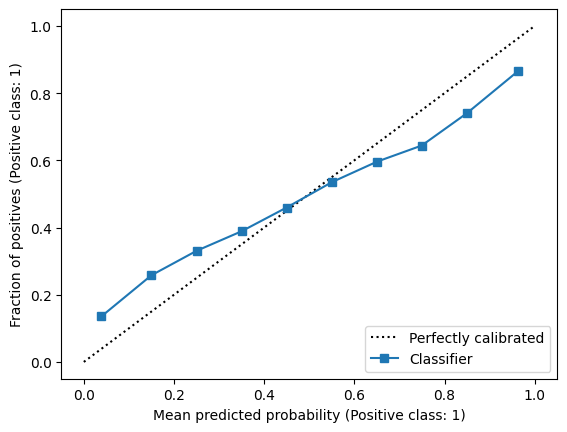

In [20]:
from sklearn.calibration import CalibrationDisplay
CalibrationDisplay.from_predictions(anal_data['playerA_wins'], anal_data['match_win_probA'], n_bins= 10)


### Confusion Matrix


In [21]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(anal_data["playerA_wins"], predicted_winnerA)
print(cm)


[[18186  8005]
 [ 7778 17916]]


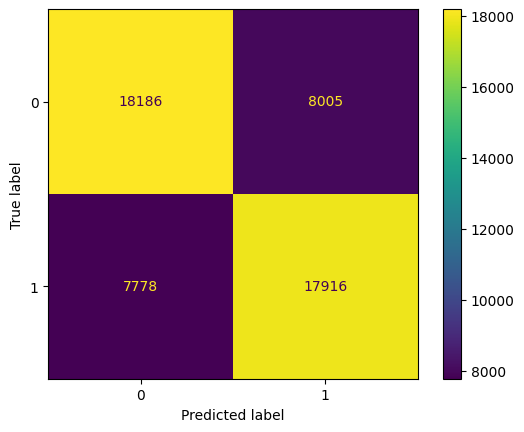

In [22]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(anal_data["playerA_wins"], predicted_winnerA)


### Histogram of Predicted Probabilities


(array([4369., 2546., 2364., 2408., 2348., 2376., 2436., 2372., 2404.,
        2341., 2326., 2409., 2350., 2384., 2471., 2363., 2447., 2356.,
        2379., 4436.]),
 array([2.33369649e-05, 5.00221411e-02, 1.00020945e-01, 1.50019749e-01,
        2.00018554e-01, 2.50017358e-01, 3.00016162e-01, 3.50014966e-01,
        4.00013770e-01, 4.50012574e-01, 5.00011378e-01, 5.50010182e-01,
        6.00008987e-01, 6.50007791e-01, 7.00006595e-01, 7.50005399e-01,
        8.00004203e-01, 8.50003007e-01, 9.00001811e-01, 9.50000616e-01,
        9.99999420e-01]),
 <BarContainer object of 20 artists>)

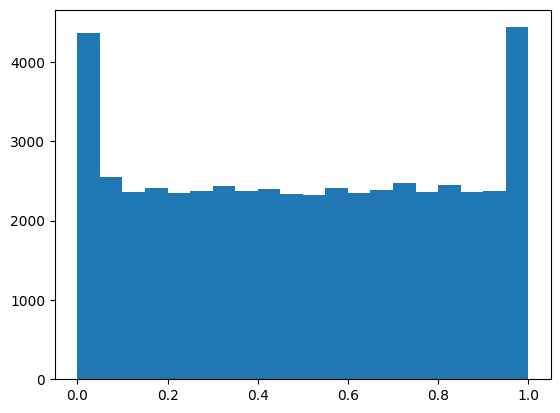

In [23]:
import matplotlib.pyplot as plt

plt.hist(anal_data["match_win_probA"], bins=20)


### ROC Curve


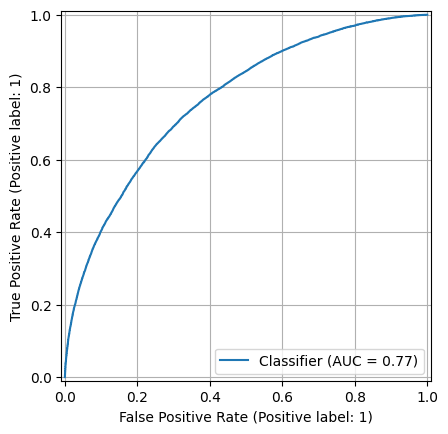

In [24]:
from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

RocCurveDisplay.from_predictions(anal_data["playerA_wins"], anal_data["match_win_probA"])
plt.grid(True)
plt.show()


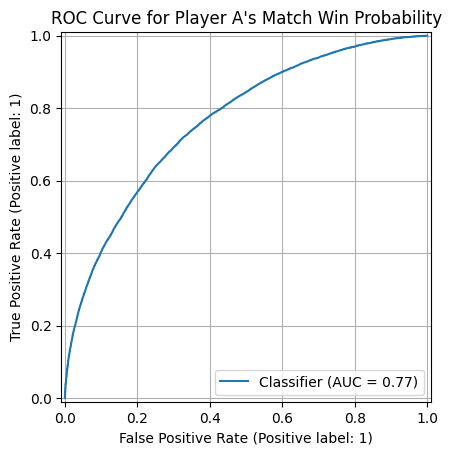

In [25]:
RocCurveDisplay.from_predictions(anal_data["playerA_wins"], anal_data["match_win_probA"])
plt.grid(True)
plt.title("ROC Curve for Player A's Match Win Probability")
plt.show()


### Saving the Predictions


In [26]:
results = pd.DataFrame({
    "playerA_win_actual": anal_data["playerA_wins"],
    "predicted_p": anal_data["p"],
    "predicted_q": anal_data["q"],
    "match_probabilityA": anal_data["match_win_probA"],
    "predicted_winner": predicted_winnerA
})

PATH = "/content/drive/MyDrive/Projects/Tennis/v1/v1_results.parquet"
joblib.dump(anal_data, PATH)


['/content/drive/MyDrive/Projects/Tennis/v1/v1_results.parquet']

# **SHAP Analysis**


## Data Check


In [44]:
from sklearn.preprocessing import StandardScaler
import gc

scaler= StandardScaler()

X_val_log_scaled= scaler.fit_transform(X_val_log)
X_val_log_scaled = pd.DataFrame(X_val_log_scaled, columns= X_val_log.columns, index= X_val_log.index)

# del X_val_log
gc.collect()


0

In [45]:
print(X_val.shape)
print(X_val_log_scaled.shape)


(25942, 246)
(25942, 246)


In [46]:
print(list(X_val.columns) == list(X_val_log_scaled.columns))


True


In [47]:
assert (X_val.columns == X_val_log_scaled.columns).all()


## SHAP


### Importing Models


In [48]:
from sklearn.preprocessing import StandardScaler
import gc
X_train_val = pd.concat([X_train, X_val], axis = 0)
y_train_valA = pd.concat([y_trainA, y_valA], axis = 0)
y_train_valB = pd.concat([y_trainB, y_valB], axis = 0)

X_train_val_log = pd.concat([X_train_log, X_val_log], axis = 0)

scaler = StandardScaler()
X_train_val_log_scaled = scaler.fit_transform(X_train_val_log)
X_train_val_log_scaled = pd.DataFrame(X_train_val_log_scaled, columns= X_train_val_log.columns, index= X_train_val_log.index)
del X_train_val_log
gc.collect()


0

In [49]:
import joblib
from google.colab import drive
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from sklearn.linear_model import Ridge
from lightgbm import LGBMRegressor

drive.mount('/content/drive')
RIDGE_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1/models/ridge_final_playerA.pkl"
XGB_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1/models/XGBoost_final_playerA.pkl"
LGB_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1/models/lightGBM_final_playerA.pkl"
CAT_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1/models/catBoost_final_playerA.pkl"

ridge_A = joblib.load(RIDGE_PATH_A)
xgb_A = joblib.load(XGB_PATH_A)
lgbm_A = joblib.load(LGB_PATH_A)
cat_A = joblib.load(CAT_PATH_A)

ridge_A.fit(X_train_val_log_scaled, y_train_valA)
xgb_A.fit(X_train_val, y_train_valA)
lgbm_A.fit(X_train_val, y_train_valA)
cat_A.fit(X_train_val, y_train_valA)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


CatBoostRegressor(depth=8, devices='0', iterations=1000, l2_leaf_reg=3, learning_rate=0.03, loss_function='RMSE', random_seed=42, task_type='CPU', verbose=False)

In [50]:
RIDGE_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1/models/ridge_final_playerB.pkl"
XGB_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1/models/XGBoost_final_playerB.pkl"
LGB_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1/models/lightGBM_final_playerB.pkl"
CAT_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1/models/catBoost_final_playerB.pkl"

ridge_B = joblib.load(RIDGE_PATH_B)
xgb_B = joblib.load(XGB_PATH_B)
lgbm_B = joblib.load(LGB_PATH_B)
cat_B = joblib.load(CAT_PATH_B)

ridge_B.fit(X_train_val_log_scaled, y_train_valB)
xgb_B.fit(X_train_val, y_train_valB)
lgbm_B.fit(X_train_val, y_train_valB)
cat_B.fit(X_train_val, y_train_valB)


CatBoostRegressor(depth=8, devices='0', iterations=1000, l2_leaf_reg=3, learning_rate=0.03, loss_function='RMSE', random_seed=42, task_type='CPU', verbose=False)

### Explainer and Background Dataset


In [51]:
bg_normal = X_train_val.sample(2000, random_state= 42)
bg_log = X_train_val_log_scaled.sample(2000, random_state= 42)


In [52]:
X_explain_normal = X_train_val.tail(2000)
X_explain_log = X_train_val_log_scaled.tail(2000)


### Values (Player A)


In [53]:
import shap
import numpy as np


In [54]:
modelsA = {
    "LightGBM": {
        "model": lgbm_A,
        "background": bg_normal,
        "data": X_explain_normal,
        "explainer": "tree"
    },

    "XGBoost": {
        "model": xgb_A,
        "background": bg_normal,
        "data": X_explain_normal,
        "explainer": "tree"
    },

    "CatBoost": {
        "model": cat_A,
        "background": bg_normal,
        "data": X_explain_normal,
        "explainer": "tree"
    },

    "Ridge": {
        "model": ridge_A,
        "background": bg_log,
        "data": X_explain_log,
        "explainer": "linear"
    }
}


In [55]:
shap_resultsA = {}

for name, cfg in modelsA.items():

    print(f"Computing SHAP for {name}...")

    if cfg["explainer"] == "tree":
        explainer = shap.TreeExplainer(cfg["model"])
    elif cfg["explainer"] == "linear":
        explainer = shap.LinearExplainer(cfg["model"], masker=cfg["background"])

    explanation = explainer(cfg["data"])

    shap_resultsA[name] = {
        "explanation": explanation,
        "values": explanation.values,
        "base_value": explanation.base_values
    }

    print(f"Done: {name}")


Computing SHAP for LightGBM...
Done: LightGBM
Computing SHAP for XGBoost...
Done: XGBoost
Computing SHAP for CatBoost...


Done: CatBoost
Computing SHAP for Ridge...
Done: Ridge


In [56]:
#test-1
shap_resultsA["LightGBM"]["values"]       
shap_resultsA["LightGBM"]["base_value"]   
shap_resultsA["LightGBM"]["explanation"]  


.values =
array([[ 1.95460181e-04,  2.87233734e-07, -9.45585224e-05, ...,
        -5.67270162e-06, -3.62746173e-05, -2.94071888e-05],
       [ 1.15635724e-04,  2.10578237e-06,  1.66767401e-04, ...,
        -6.65716127e-06, -1.55534864e-04, -2.99864560e-04],
       [ 1.94375140e-04, -2.72859710e-07, -8.36565276e-05, ...,
         1.70939288e-05,  3.65488718e-04, -1.94250898e-05],
       ...,
       [-6.18274514e-04, -1.77957857e-06, -6.98930511e-05, ...,
        -4.15331644e-06, -4.18107786e-05, -3.22653345e-05],
       [-1.31436601e-03, -1.86736402e-06, -3.77565815e-05, ...,
        -4.24692000e-06, -4.24032814e-05, -1.42242572e-05],
       [-3.62508263e-04,  5.98608432e-06, -1.60207510e-04, ...,
        -1.06756193e-05, -8.19705371e-05, -1.54595414e-05]])

.base_values =
array([0.62078122, 0.62078122, 0.62078122, ..., 0.62078122, 0.62078122,
       0.62078122])

.data =
array([[ 32.,   3.,   8., ...,   0.,   1.,   0.],
       [ 32.,   3.,   4., ...,   0.,   1.,   0.],
       [ 32.,   

In [57]:
ensemble_shap_valuesA = np.mean([
        shap_resultsA["LightGBM"]["values"],
        shap_resultsA["XGBoost"]["values"],
        shap_resultsA["CatBoost"]["values"],
        shap_resultsA["Ridge"]["values"],
        ], axis=0)


In [58]:
ensemble_base_valuesA = np.mean([
        shap_resultsA["LightGBM"]["base_value"],
        shap_resultsA["XGBoost"]["base_value"],
        shap_resultsA["CatBoost"]["base_value"],
        shap_resultsA["Ridge"]["base_value"],
    ], axis=0)


In [59]:
#SHAP Explanation Object
ensemble_explanationA = shap.Explanation(
    values=ensemble_shap_valuesA,
    base_values=ensemble_base_valuesA,
    data=X_explain_normal.values,
    feature_names=X_explain_normal.columns.tolist(),
)


In [60]:
#test-2
print(type(ensemble_explanationA))
print(ensemble_explanationA.values.shape)
print(len(ensemble_explanationA.feature_names))


<class 'shap._explanation.Explanation'>
(2000, 246)
246


In [61]:
#test-3
ensemble_predictionsA = (
    lgbm_A.predict(X_explain_normal)
    + xgb_A.predict(X_explain_normal)
    + cat_A.predict(X_explain_normal)
    + ridge_A.predict(X_explain_log)
) / 4

reconstructed_predictionsA = ensemble_explanationA.base_values + ensemble_explanationA.values.sum(axis=1)


max_errorA = np.max(np.abs(ensemble_predictionsA - reconstructed_predictionsA))

print(f"Maximum reconstruction error: {max_errorA:.10f}")


Maximum reconstruction error: 0.0000004539


In [62]:
#test-4
print(len(ensemble_explanationA.feature_names))
print(ensemble_explanationA.values.shape[1])


246
246


In [63]:
#test-5
print(ensemble_explanationA.values.shape)
print(ensemble_explanationA.data.shape)


(2000, 246)
(2000, 246)


### Values (Player B)


In [64]:
import numpy as np
import shap


In [65]:
modelsB = {
    "LightGBM": {
        "model": lgbm_B,
        "background": bg_normal,
        "data": X_explain_normal,
        "explainer": "tree"
    },

    "XGBoost": {
        "model": xgb_B,
        "background": bg_normal,
        "data": X_explain_normal,
        "explainer": "tree"
    },

    "CatBoost": {
        "model": cat_B,
        "background": bg_normal,
        "data": X_explain_normal,
        "explainer": "tree"
    },

    "Ridge": {
        "model": ridge_B,
        "background": bg_log,
        "data": X_explain_log,
        "explainer": "linear"
    }
}


In [66]:
shap_resultsB = {}

for name, cfg in modelsB.items():

    print(f"Computing SHAP for {name}...")

    if cfg["explainer"] == "tree":
        explainer = shap.TreeExplainer(cfg["model"])
    elif cfg["explainer"] == "linear":
        explainer = shap.LinearExplainer(cfg["model"], masker=cfg["background"])

    explanation = explainer(cfg["data"])

    shap_resultsB[name] = {
        "explanation": explanation,
        "values": explanation.values,
        "base_value": explanation.base_values
    }

    print(f"Done: {name}")


Computing SHAP for LightGBM...
Done: LightGBM
Computing SHAP for XGBoost...
Done: XGBoost
Computing SHAP for CatBoost...


Done: CatBoost
Computing SHAP for Ridge...
Done: Ridge


In [67]:
#test-1
shap_resultsB["LightGBM"]["values"]       
shap_resultsB["LightGBM"]["base_value"]   
shap_resultsB["LightGBM"]["explanation"]  


.values =
array([[ 3.97136266e-04, -7.44393832e-07,  1.05692944e-04, ...,
        -1.92894241e-05, -1.57622993e-05,  9.28159154e-05],
       [ 1.89338613e-04,  9.54363711e-07, -1.10148307e-04, ...,
        -2.60265026e-05,  1.01981743e-05,  1.46825346e-03],
       [ 1.98337301e-04,  3.66676203e-06,  9.40919585e-05, ...,
         2.30536036e-04,  9.17909248e-06,  1.15812967e-04],
       ...,
       [-2.39911530e-03, -1.83657774e-06,  4.41114056e-05, ...,
        -2.67658784e-05, -5.92385689e-06,  5.79592013e-05],
       [-1.46636601e-03, -1.56576339e-06,  7.13038599e-05, ...,
        -2.22624524e-05, -3.20878315e-05,  4.46321477e-05],
       [-1.04130347e-03, -1.40282275e-06,  9.21271524e-05, ...,
        -1.77048901e-05, -3.30377124e-06,  4.46020187e-05]])

.base_values =
array([0.62073834, 0.62073834, 0.62073834, ..., 0.62073834, 0.62073834,
       0.62073834])

.data =
array([[ 32.,   3.,   8., ...,   0.,   1.,   0.],
       [ 32.,   3.,   4., ...,   0.,   1.,   0.],
       [ 32.,   

In [68]:
ensemble_shap_valuesB = np.mean([
        shap_resultsB["LightGBM"]["values"],
        shap_resultsB["XGBoost"]["values"],
        shap_resultsB["CatBoost"]["values"],
        shap_resultsB["Ridge"]["values"],
        ], axis=0)


In [69]:
ensemble_base_valuesB = np.mean([
        shap_resultsB["LightGBM"]["base_value"],
        shap_resultsB["XGBoost"]["base_value"],
        shap_resultsB["CatBoost"]["base_value"],
        shap_resultsB["Ridge"]["base_value"],
    ], axis=0)


In [70]:
#SHAP Explanation Object
ensemble_explanationB = shap.Explanation(
    values=ensemble_shap_valuesB,
    base_values=ensemble_base_valuesB,
    data=X_explain_normal.values,
    feature_names=X_explain_normal.columns.tolist(),
)


In [71]:
#test-2
print(type(ensemble_explanationB))
print(ensemble_explanationB.values.shape)
print(len(ensemble_explanationB.feature_names))


<class 'shap._explanation.Explanation'>
(2000, 246)
246


In [72]:
#test-3
ensemble_predictionsB = (
    lgbm_B.predict(X_explain_normal)
    + xgb_B.predict(X_explain_normal)
    + cat_B.predict(X_explain_normal)
    + ridge_B.predict(X_explain_log)
) / 4

reconstructed_predictionsB = ensemble_explanationB.base_values + ensemble_explanationB.values.sum(axis=1)


max_errorB = np.max(np.abs(ensemble_predictionsB - reconstructed_predictionsB))

print(f"Maximum reconstruction error: {max_errorB:.10f}")


Maximum reconstruction error: 0.0000004466


In [73]:
#test-4
print(len(ensemble_explanationB.feature_names))
print(ensemble_explanationB.values.shape[1])


246
246


In [74]:
#test-5
print(ensemble_explanationB.values.shape)
print(ensemble_explanationB.data.shape)


(2000, 246)
(2000, 246)


### Plots


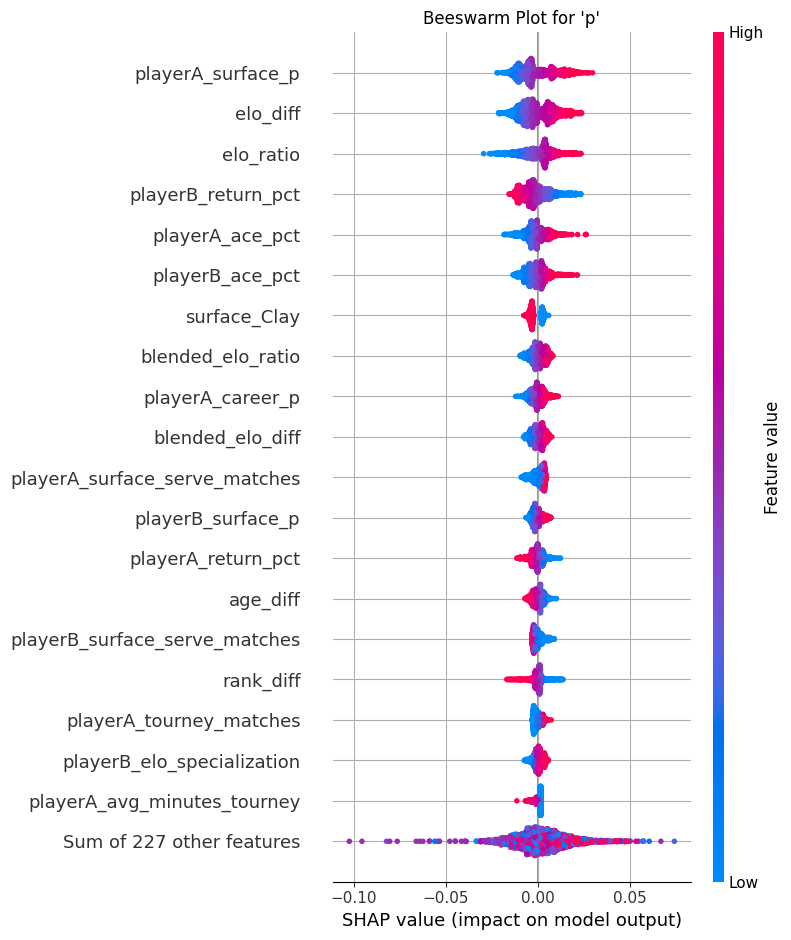

In [75]:
#Beeswarm player A
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

shap.plots.beeswarm(ensemble_explanationA, max_display=20, show=False)

plt.title("Beeswarm Plot for 'p'")
plt.grid()
plt.tight_layout()
plt.show()


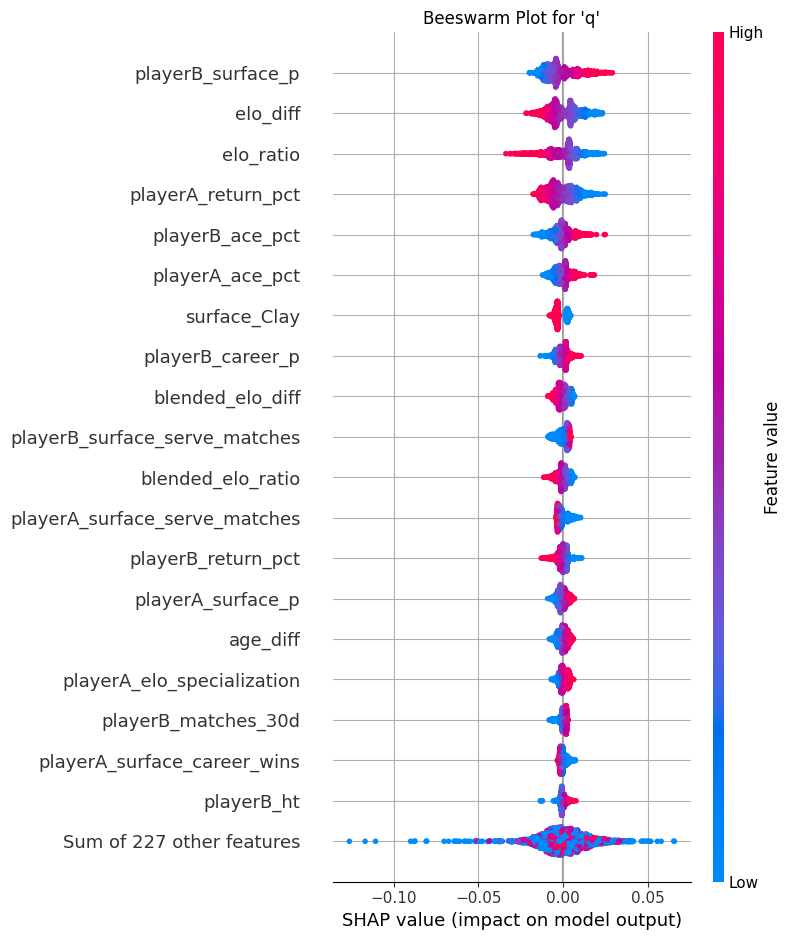

In [76]:
#Beeswarm player B
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

shap.plots.beeswarm(ensemble_explanationB, max_display=20, show=False)

plt.title("Beeswarm Plot for 'q'")
plt.grid()
plt.tight_layout()
plt.show()


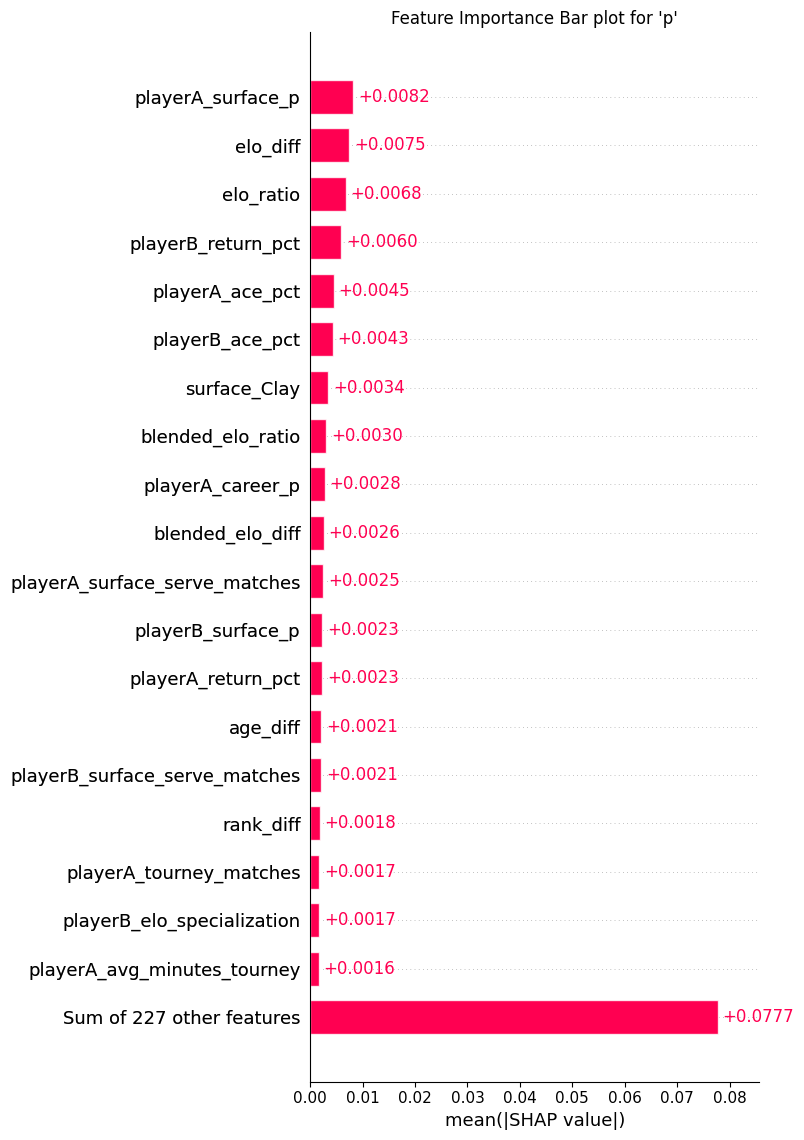

In [77]:
import numpy as np
import matplotlib.pyplot as plt
import shap

max_display = 20

plt.figure(figsize=(10, 8))

# 1. Generate the plot without rendering it immediately
shap.plots.bar(ensemble_explanationA, max_display=max_display, show=False)

# 2. Extract and sort the mean absolute SHAP values
values = np.abs(ensemble_explanationA.values).mean(0)
sorted_indices = np.argsort(values)[::-1]
sorted_values = values[sorted_indices]

# 3. Separate the top features from the remainder
# For max_display=20, the first 19 are shown individually, and the rest are summed
num_individual_features = max_display - 1
top_values = sorted_values[:num_individual_features]
remainder_sum = np.sum(sorted_values[num_individual_features:])

# 4. Get the text labels from the plot (ordered top-to-bottom)
ax = plt.gca()
labels = [t for t in ax.texts if t.get_text().startswith('+') or t.get_text().startswith('-')]

# 5. Correctly apply the precision formatting
for i, label in enumerate(labels):
    if i < len(top_values):
        # Individual features
        label.set_text(f"+{top_values[i]:.4f}")
    else:
        # The final summary bar at the bottom
        label.set_text(f"+{remainder_sum:.4f}")
        break  # Prevent updating any stray text elements

plt.title("Feature Importance Bar plot for 'p'")
plt.tight_layout()
plt.show()


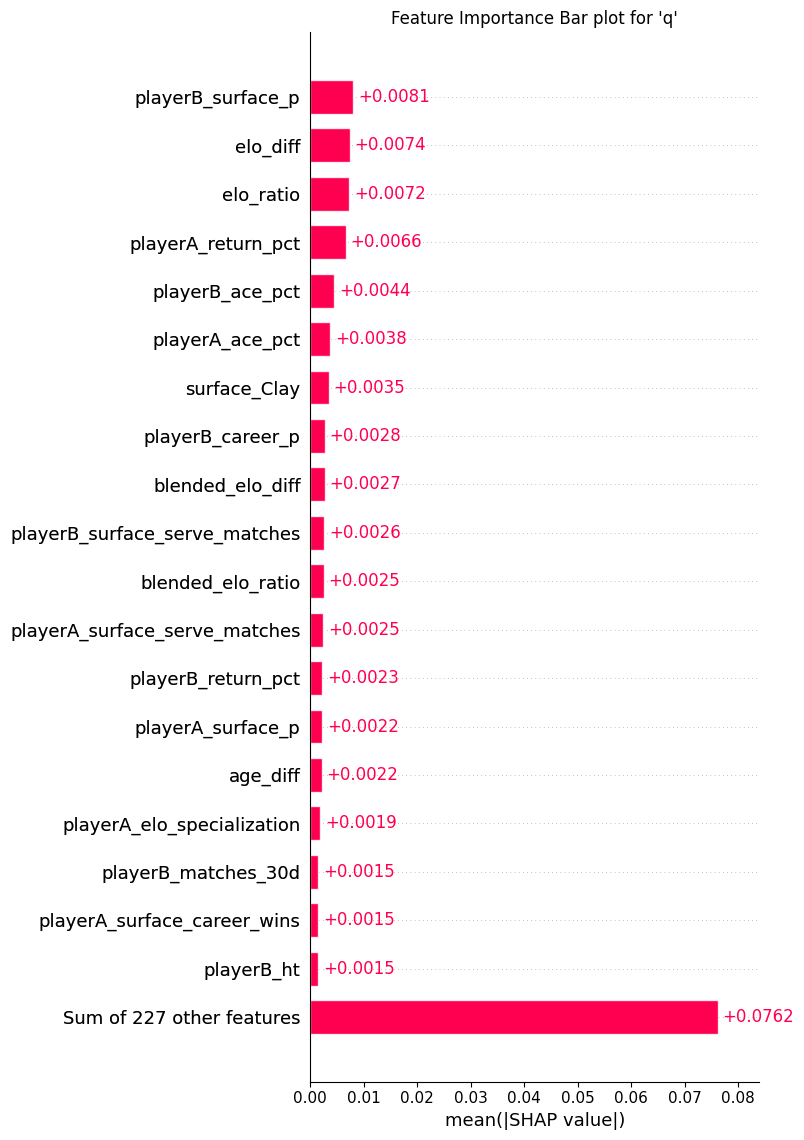

In [78]:
#player B
import numpy as np
import matplotlib.pyplot as plt
import shap

max_display = 20

plt.figure(figsize=(10, 8))

# 1. Generate the plot without rendering it immediately
shap.plots.bar(ensemble_explanationB, max_display=max_display, show=False)

# 2. Extract and sort the mean absolute SHAP values
values = np.abs(ensemble_explanationB.values).mean(0)
sorted_indices = np.argsort(values)[::-1]
sorted_values = values[sorted_indices]

# 3. Separate the top features from the remainder
# For max_display=20, the first 19 are shown individually, and the rest are summed
num_individual_features = max_display - 1
top_values = sorted_values[:num_individual_features]
remainder_sum = np.sum(sorted_values[num_individual_features:])

# 4. Get the text labels from the plot (ordered top-to-bottom)
ax = plt.gca()
labels = [t for t in ax.texts if t.get_text().startswith('+') or t.get_text().startswith('-')]

# 5. Correctly apply the precision formatting
for i, label in enumerate(labels):
    if i < len(top_values):
        # Individual features
        label.set_text(f"+{top_values[i]:.4f}")
    else:
        # The final summary bar at the bottom
        label.set_text(f"+{remainder_sum:.4f}")
        break  # Prevent updating any stray text elements

plt.title("Feature Importance Bar plot for 'q'")
plt.tight_layout()
plt.show()


### Feature Ranking Table 


In [79]:
#top 10 player A
mean_abs_shap = np.abs(ensemble_explanationA.values).mean(axis=0)

importance_dfA = (pd.DataFrame({"Feature": ensemble_explanationA.feature_names, "Mean |SHAP|": mean_abs_shap})
                 .sort_values("Mean |SHAP|", ascending=False).reset_index(drop=True))

top10 = importance_dfA.head(10)

print(top10)


              Feature  Mean |SHAP|
0   playerA_surface_p     0.008179
1            elo_diff     0.007488
2           elo_ratio     0.006767
3  playerB_return_pct     0.005962
4     playerA_ace_pct     0.004515
5     playerB_ace_pct     0.004300
6        surface_Clay     0.003390
7   blended_elo_ratio     0.003046
8    playerA_career_p     0.002793
9    blended_elo_diff     0.002584


In [80]:
# Save as CSV 
PATH_CSV = "/content/drive/MyDrive/Projects/Tennis/v1/SHAP/v1_playerA_all_shap_importance.csv"
importance_dfA.to_csv(PATH_CSV, index=False)


In [81]:
#top 10 player B
mean_abs_shap = np.abs(ensemble_explanationB.values).mean(axis=0)

importance_dfB = (pd.DataFrame({"Feature": ensemble_explanationB.feature_names, "Mean |SHAP|": mean_abs_shap})
                 .sort_values("Mean |SHAP|", ascending=False).reset_index(drop=True))

top10 = importance_dfB.head(10)

print(top10)


                         Feature  Mean |SHAP|
0              playerB_surface_p     0.008063
1                       elo_diff     0.007420
2                      elo_ratio     0.007250
3             playerA_return_pct     0.006617
4                playerB_ace_pct     0.004443
5                playerA_ace_pct     0.003784
6                   surface_Clay     0.003485
7               playerB_career_p     0.002754
8               blended_elo_diff     0.002713
9  playerB_surface_serve_matches     0.002605


In [82]:
# Save as CSV 
PATH_CSV = "/content/drive/MyDrive/Projects/Tennis/v1/SHAP/v1_playerB_all_shap_importance.csv"
importance_dfB.to_csv(PATH_CSV, index=False)


### Feature Group Based Importance


In [83]:
feature_groups = {
    "Ranking": ["playerA_rank_filled", "playerB_rank_filled", "playerA_is_unranked", "playerB_is_unranked", "playerA_rank_points_missing", 
                "playerB_rank_points_missing", "rank_diff", "rank_ratio", "playerA_points_filled", "playerB_points_filled", "playerA_top10", 
                "playerB_top10", "playerA_top32", "playerB_top32", "playerA_top64", "playerB_top64", "playerA_top100", "playerB_top100"], 

    "Elo": ["playerA_elo", "playerB_elo", "elo_diff", "playerA_surface_elo", "playerB_surface_elo", "surface_elo_diff", 
            'playerA_blended_elo', 'playerB_blended_elo', 'blended_elo_diff', 'elo_ratio', 'playerA_elo_momentum', 'playerB_elo_momentum', 
            'playerA_elo_volatility', 'playerB_elo_volatility', 'blended_elo_ratio', 'surface_elo_ratio'], 

    "Form": ["playerA_last10_wins", 
             "playerB_last10_wins", "playerA_last10_matches", "playerB_last10_matches", "playerA_last10_pct", "playerB_last10_pct", 
             "playerA_last25_wins", "playerB_last25_wins", "playerA_last25_matches", "playerB_last25_matches", "playerA_last25_pct", 
             "playerB_last25_pct", "playerA_surface10_wins", "playerB_surface10_wins", "playerA_surface10_matches", 
             "playerB_surface10_matches", "playerA_surface10_pct", "playerB_surface10_pct", "playerA_surface25_wins", 
             "playerB_surface25_wins", "playerA_surface25_matches", "playerB_surface25_matches", "playerA_surface25_pct", 
             "playerB_surface25_pct", "playerA_52w_wins", "playerB_52w_wins", "playerA_52w_matches", "playerB_52w_matches", 
             "playerA_52w_pct", "playerB_52w_pct", "playerA_career_matches", "playerB_career_matches", "playerA_surface_career_matches", 
             "playerB_surface_career_matches", "playerA_last10_losses", "playerB_last10_losses", "playerA_last25_losses", 
             "playerB_last25_losses", "playerA_surface10_losses", "playerB_surface10_losses", "playerA_surface25_losses", 
             "playerB_surface25_losses", "playerA_52w_losses", "playerB_52w_losses"], 

    "Matchup": ["playerA_h2h_wins", "playerB_h2h_wins", "h2h_total", "h2h_diff", "playerA_surface_h2h_wins", "playerB_surface_h2h_wins", 
                "surface_h2h_total", "surface_h2h_diff", "playerA_last5_h2h_wins", "playerB_last5_h2h_wins", "last5_h2h_total", 
                "last5_h2h_diff", "playerA_top20_wins", "playerB_top20_wins", "playerA_top20_losses", "playerB_top20_losses", 
                "playerA_top20_win_pct", "playerB_top20_win_pct", "playerA_hand_wins", "playerB_hand_wins", "playerA_hand_losses", 
                "playerB_hand_losses", "playerA_hand_win_pct", "playerB_hand_win_pct", 'playerA_top20_total', 'playerB_top20_total', 
                'playerA_hand_total', 'playerB_hand_total'], 

    "Fatigue":  ["playerA_matches_7d", "playerB_matches_7d", "playerA_matches_30d", "playerB_matches_30d", "playerA_wins_7d", 
                 "playerB_wins_7d", "playerA_wins_30d", "playerB_wins_30d", "playerA_winpct_7d", "playerB_winpct_7d", 
                 "playerA_winpct_30d", "playerB_winpct_30d", "playerA_minutes_tourney", "playerB_minutes_tourney", 
                 "playerA_avg_minutes_tourney", "playerB_avg_minutes_tourney", "playerA_losses_7d", "playerB_losses_7d", 
                 "playerA_losses_30d", "playerB_losses_30d"], 

    "Serve": ["playerA_ace_pct", "playerB_ace_pct", "playerA_df_pct", "playerB_df_pct", "playerA_1stIn_pct", "playerB_1stIn_pct", 
              "playerA_1stWon_pct", "playerB_1stWon_pct", "playerA_2ndWon_pct", "playerB_2ndWon_pct", "playerA_career_p", 
              "playerB_career_p", "playerA_serve_matches", "playerB_serve_matches", "playerA_matchup_p", "playerB_matchup_p", 
              "playerA_matchup_service_points", "playerB_matchup_service_points", "playerA_surface_p", "playerB_surface_p", 
              "playerA_surface_serve_matches", "playerB_surface_serve_matches"], 

    "Return": ["playerA_return_pct", "playerB_return_pct", "playerA_bp_convert_pct", "playerB_bp_convert_pct", "playerA_return_matches", 
               "playerB_return_matches"], 

    "Physical":  ['playerA_hand_A', 'playerA_hand_L', 'playerA_hand_R', 'playerA_hand_U', 'playerB_hand_A', 'playerB_hand_L', 
                  'playerB_hand_R','playerB_hand_U', "playerA_age", "playerB_age", "age_diff", "playerA_ht", "playerB_ht", "height_diff"],

    "Seed":  ["playerA_seeded", "playerB_seeded", "seed_diff", "seed_diff_missing"], 

    "Surface Specialization": ["playerA_win_rate_specialization", "playerB_win_rate_specialization", "playerA_elo_specialization", 
                               "playerB_elo_specialization", "playerA_serve_specialization", "playerB_serve_specialization"],

    "Experience": ["playerA_career_wins", "playerB_career_wins", "playerA_career_losses", "playerB_career_losses", "playerA_career_matches",
                    "playerA_career_pct", "playerB_career_matches", "playerA_surface_career_matches", "playerB_surface_career_matches",
                    "playerB_career_pct", "playerA_surface_career_wins", "playerB_surface_career_wins", "playerA_surface_career_losses", 
                    "playerB_surface_career_losses", "playerA_surface_career_pct", "playerB_surface_career_pct","playerA_level_wins", 
                    "playerB_level_wins", "playerA_level_losses", "playerB_level_losses", "playerA_level_win_pct", 
                   "playerA_tourney_matches", "playerB_tourney_matches", "playerA_level_matches", "playerB_level_matches", 
                   "playerB_level_win_pct"], 

    "Tournament Context": ["draw_size", "best_of", 'playerA_entry_ALT', 'playerA_entry_ITF', 'playerA_entry_LL', 
                           'playerA_entry_NONE', 'playerA_entry_OTHER', 'playerA_entry_PR', 'playerA_entry_Q', 'playerA_entry_SE', 
                           'playerA_entry_WC', 'playerB_entry_ALT', 'playerB_entry_ITF', 'playerB_entry_LL', 'playerB_entry_NONE', 
                           'playerB_entry_OTHER', 'playerB_entry_PR', 'playerB_entry_Q', 'playerB_entry_SE', 'playerB_entry_WC',
                           'round_BR', 'round_ER', 'round_F', 'round_Q1', 'round_Q2', 'round_Q3', 'round_QF', 'round_R128', 'round_R16', 
                           'round_R32', 'round_R64', 'round_RR', 'round_SF', 'tourney_level_A', 'tourney_level_C', 'tourney_level_D', 
                           'tourney_level_F', 'tourney_level_G', 'tourney_level_M', 'surface_Carpet', 'surface_Clay', 'surface_Grass', 
                           'surface_Hard',]
}


In [84]:
group_importanceA = {}

for group_name, features in feature_groups.items():
    cols = [
        ensemble_explanationA.feature_names.index(f)
        for f in features
        if f in ensemble_explanationA.feature_names
    ]

    group_importanceA[group_name] = (np.abs(ensemble_explanationA.values[:, cols]).mean(axis=0).sum())


group_importanceB = {}

for group_name, features in feature_groups.items():
    cols = [
        ensemble_explanationB.feature_names.index(f)
        for f in features
        if f in ensemble_explanationB.feature_names
    ]

    group_importanceB[group_name] = (np.abs(ensemble_explanationB.values[:, cols]).mean(axis=0).sum())


In [85]:
group_dfA = (pd.DataFrame({
        "Feature Group": group_importanceA.keys(),
        "Importance": group_importanceA.values()
    })
    .sort_values("Importance", ascending=False)
    )

group_dfB = (pd.DataFrame({
        "Feature Group": group_importanceB.keys(),
        "Importance": group_importanceB.values()
    })
    .sort_values("Importance", ascending=False)
    )


In [86]:
group_dfA["Percentage"] = 100*group_dfA["Importance"]/group_dfA["Importance"].sum()
group_dfB["Percentage"] = 100*group_dfB["Importance"]/group_dfB["Importance"].sum()


In [87]:
PATH_CSV_A = "/content/drive/MyDrive/Projects/Tennis/v1/SHAP/v1_playerA_groupwise_shap_importance.csv"
group_dfA.to_csv(PATH_CSV_A,index=False)

PATH_CSV_B = "/content/drive/MyDrive/Projects/Tennis/v1/SHAP/v1_playerB_groupwise_shap_importance.csv"
group_dfB.to_csv(PATH_CSV_B,index=False)


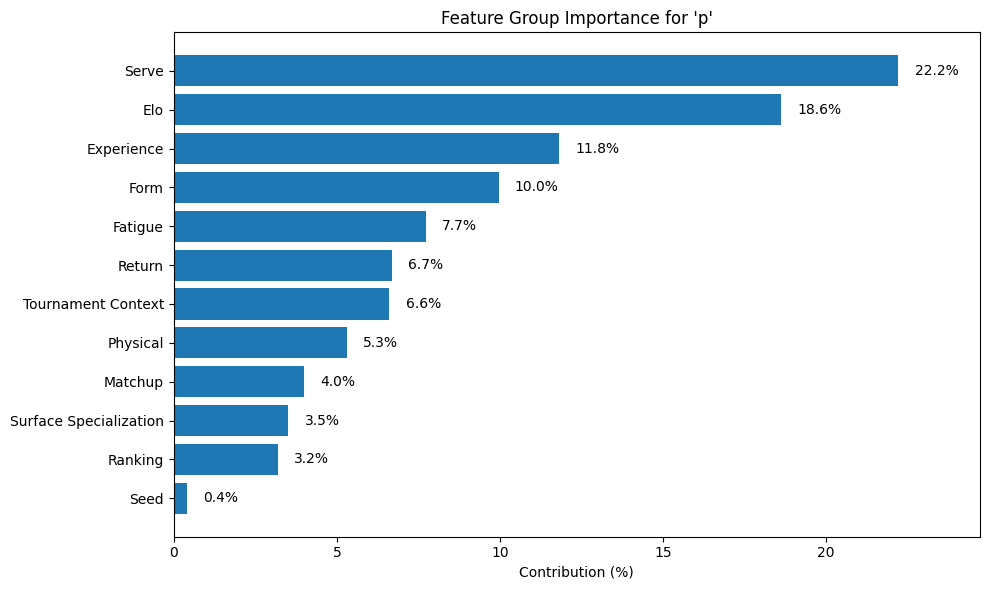

In [88]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# Create the horizontal bar chart
bars = plt.barh(group_dfA["Feature Group"], group_dfA["Percentage"])

# Add labels
plt.xlabel("Contribution (%)")
plt.title("Feature Group Importance for 'p'")
plt.gca().invert_yaxis() # Highest percentage at the top

# Add percentage text in front of each bar
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 0.5,                          # x-position (slightly to the right of the bar)
        bar.get_y() + bar.get_height() / 2,  # y-position (center of the bar)
        f'{width:.1f}%',                      # format to 1 decimal place
        va='center'                            # vertical alignment
    )

# --- FIX: Dynamically add extra breathing room to the right side ---
max_width = group_dfA["Percentage"].max()
plt.xlim(0, max_width + 2.5)  # Adds a 2.5% padding margin past the longest bar

# plt.grid()
plt.tight_layout()
plt.show()


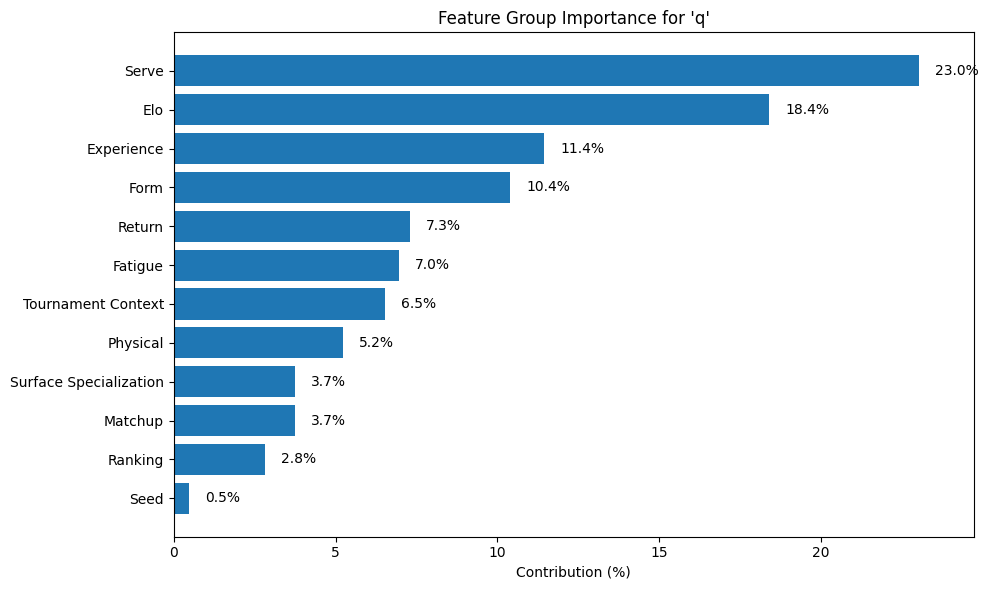

In [89]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# Create the horizontal bar chart
bars = plt.barh(group_dfB["Feature Group"], group_dfB["Percentage"])

# Add labels
plt.xlabel("Contribution (%)")
plt.title("Feature Group Importance for 'q'")
plt.gca().invert_yaxis() # Highest percentage at the top

# Add percentage text in front of each bar
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 0.5,                          # x-position (slightly to the right of the bar)
        bar.get_y() + bar.get_height() / 2,  # y-position (center of the bar)
        f'{width:.1f}%',                      # format to 1 decimal place
        va='center'                            # vertical alignment
    )

# --- FIX: Dynamically add extra breathing room to the right side ---
max_width = group_dfA["Percentage"].max()
plt.xlim(0, max_width + 2.5)  # Adds a 2.5% padding margin past the longest bar

# plt.grid()
plt.tight_layout()
plt.show()


In [90]:
list(X_train.columns)


['draw_size',
 'best_of',
 'playerA_seed',
 'playerB_seed',
 'playerA_ht',
 'playerB_ht',
 'playerA_age',
 'playerB_age',
 'playerA_rank_points',
 'playerB_rank_points',
 'playerA_h2h_wins',
 'playerB_h2h_wins',
 'h2h_total',
 'h2h_diff',
 'playerA_surface_h2h_wins',
 'playerB_surface_h2h_wins',
 'surface_h2h_total',
 'surface_h2h_diff',
 'playerA_last5_h2h_wins',
 'playerB_last5_h2h_wins',
 'last5_h2h_total',
 'last5_h2h_diff',
 'playerA_top20_wins',
 'playerA_top20_losses',
 'playerA_top20_total',
 'playerA_top20_win_pct',
 'playerB_top20_wins',
 'playerB_top20_losses',
 'playerB_top20_total',
 'playerB_top20_win_pct',
 'playerA_hand_wins',
 'playerA_hand_losses',
 'playerA_hand_total',
 'playerA_hand_win_pct',
 'playerB_hand_wins',
 'playerB_hand_losses',
 'playerB_hand_total',
 'playerB_hand_win_pct',
 'playerA_elo',
 'playerB_elo',
 'elo_diff',
 'playerA_surface_elo',
 'playerB_surface_elo',
 'surface_elo_diff',
 'playerA_blended_elo',
 'playerB_blended_elo',
 'blended_elo_diff',


# **Permutation**


In [91]:
import numpy as np

class EqualWeightedEnsemble:
    def __init__(self, lightgbm, xgboost, catboost, ridge):
        self.lightgbm = lightgbm
        self.xgboost = xgboost
        self.catboost = catboost
        self.ridge = ridge

    def predict(self, X_normal, X_log):
        pred_lgb = self.lightgbm.predict(X_normal)
        pred_xgb = self.xgboost.predict(X_normal)
        pred_cat = self.catboost.predict(X_normal)
        pred_ridge = self.ridge.predict(X_log)

        return (pred_lgb + pred_xgb + pred_cat + pred_ridge)/4


### Loading Models


In [92]:
from sklearn.preprocessing import StandardScaler
import gc
X_train_val = pd.concat([X_train, X_val], axis = 0)
y_train_valA = pd.concat([y_trainA, y_valA], axis = 0)
y_train_valB = pd.concat([y_trainB, y_valB], axis = 0)

X_train_val_log = pd.concat([X_train_log, X_val_log], axis = 0)

scaler = StandardScaler()
X_train_val_log_scaled = scaler.fit_transform(X_train_val_log)
X_train_val_log_scaled = pd.DataFrame(X_train_val_log_scaled, columns= X_train_val_log.columns, index= X_train_val_log.index)
del X_train_val_log
gc.collect()


4487

In [93]:
import joblib
from google.colab import drive
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from sklearn.linear_model import Ridge
from lightgbm import LGBMRegressor

drive.mount('/content/drive')
RIDGE_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1/models/ridge_final_playerA.pkl"
XGB_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1/models/XGBoost_final_playerA.pkl"
LGB_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1/models/lightGBM_final_playerA.pkl"
CAT_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1/models/catBoost_final_playerA.pkl"

ridge_A = joblib.load(RIDGE_PATH_A)
xgb_A = joblib.load(XGB_PATH_A)
lgbm_A = joblib.load(LGB_PATH_A)
cat_A = joblib.load(CAT_PATH_A)

ridge_A.fit(X_train_val_log_scaled, y_train_valA)
xgb_A.fit(X_train_val, y_train_valA)
lgbm_A.fit(X_train_val, y_train_valA)
cat_A.fit(X_train_val, y_train_valA)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


CatBoostRegressor(depth=8, devices='0', iterations=1000, l2_leaf_reg=3, learning_rate=0.03, loss_function='RMSE', random_seed=42, task_type='CPU', verbose=False)

In [94]:
RIDGE_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1/models/ridge_final_playerB.pkl"
XGB_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1/models/XGBoost_final_playerB.pkl"
LGB_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1/models/lightGBM_final_playerB.pkl"
CAT_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1/models/catBoost_final_playerB.pkl"

ridge_B = joblib.load(RIDGE_PATH_B)
xgb_B = joblib.load(XGB_PATH_B)
lgbm_B = joblib.load(LGB_PATH_B)
cat_B = joblib.load(CAT_PATH_B)

ridge_B.fit(X_train_val_log_scaled, y_train_valB)
xgb_B.fit(X_train_val, y_train_valB)
lgbm_B.fit(X_train_val, y_train_valB)
cat_B.fit(X_train_val, y_train_valB)


CatBoostRegressor(depth=8, devices='0', iterations=1000, l2_leaf_reg=3, learning_rate=0.03, loss_function='RMSE', random_seed=42, task_type='CPU', verbose=False)

### Explainer and Background Dataset


In [95]:
bg_normal = X_train_val.sample(2000, random_state= 42)
bg_log = X_train_val_log_scaled.sample(2000, random_state= 42)


In [96]:
X_explain_normal = X_train_val.tail(2000)
X_explain_log = X_train_val_log_scaled.tail(2000)

y_explainA= y_train_valA.tail(2000)
y_explainB= y_train_valB.tail(2000)


### Baseline Score


In [97]:
from sklearn.metrics import mean_absolute_error

ensembleA = EqualWeightedEnsemble(lgbm_A, xgb_A, cat_A, ridge_A)

baseline_predictionsA = ensembleA.predict(X_explain_normal, X_explain_log)

baseline_maeA = mean_absolute_error(y_explainA, baseline_predictionsA)

print(baseline_maeA)


0.06060730204904692


In [98]:
from sklearn.metrics import mean_absolute_error

ensembleB = EqualWeightedEnsemble(lgbm_B, xgb_B, cat_B, ridge_B)

baseline_predictionsB = ensembleB.predict(X_explain_normal, X_explain_log)

baseline_maeB = mean_absolute_error(y_explainB, baseline_predictionsB)

print(baseline_maeB)


0.057858665977548865


### Permutation Loop


In [99]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error

# 1. Define the number of repeats for stability
n_repeats = 10
feature_importanceA = []
features = X_explain_normal.columns

# 3. Main Permutation Loop
for feature in features:
    mae_increases = []
    
    # Get the column index
    col_idx = X_explain_normal.columns.get_loc(feature)
    
    for repeat in range(n_repeats):
        # Create copies to avoid modifying original data
        X_test_permuted = X_explain_normal.copy()
        X_log_permuted = X_explain_log.copy()
        
        # Generate random permutation indices
        perm_indices = np.random.permutation(len(X_explain_normal))
        
        # Apply the SAME permutation to the specific column in both matrices
        X_test_permuted.iloc[:, col_idx] = X_test_permuted.iloc[perm_indices, col_idx].values
        X_log_permuted.iloc[:, col_idx] = X_log_permuted.iloc[perm_indices, col_idx].values
        
        # Predict with permuted data
        permuted_preds = ensembleA.predict(X_test_permuted, X_log_permuted)
        
        # Calculate new MAE and the increase
        permuted_mae = mean_absolute_error(y_explainA, permuted_preds)
        mae_increases.append(permuted_mae - baseline_maeA)
    
    # Store average importance for this feature
    feature_importanceA.append(np.mean(mae_increases))
    print(f"Finished {feature}")

# 4. Create the DataFrame
pfi_dfA = pd.DataFrame({
    "Feature": features,
    "Permutation Importance": feature_importanceA}).sort_values("Permutation Importance", ascending=False).reset_index(drop=True)

PATH_CSV_A = "/content/drive/MyDrive/Projects/Tennis/v1/Permutation/v1_playerA_permutation_importance.csv"
pfi_dfA.to_csv(PATH_CSV_A, index= False)


Finished draw_size
Finished best_of
Finished playerA_seed
Finished playerB_seed
Finished playerA_ht
Finished playerB_ht
Finished playerA_age
Finished playerB_age
Finished playerA_rank_points
Finished playerB_rank_points
Finished playerA_h2h_wins
Finished playerB_h2h_wins
Finished h2h_total
Finished h2h_diff
Finished playerA_surface_h2h_wins
Finished playerB_surface_h2h_wins
Finished surface_h2h_total
Finished surface_h2h_diff
Finished playerA_last5_h2h_wins
Finished playerB_last5_h2h_wins
Finished last5_h2h_total
Finished last5_h2h_diff
Finished playerA_top20_wins
Finished playerA_top20_losses
Finished playerA_top20_total
Finished playerA_top20_win_pct
Finished playerB_top20_wins
Finished playerB_top20_losses
Finished playerB_top20_total
Finished playerB_top20_win_pct
Finished playerA_hand_wins
Finished playerA_hand_losses
Finished playerA_hand_total
Finished playerA_hand_win_pct
Finished playerB_hand_wins
Finished playerB_hand_losses
Finished playerB_hand_total
Finished playerB_hand_w

In [100]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error

# 1. Define the number of repeats for stability
n_repeats = 10
feature_importanceB = []
features = X_explain_normal.columns

# 3. Main Permutation Loop
for feature in features:
    mae_increases = []
    
    # Get the column index
    col_idx = X_explain_normal.columns.get_loc(feature)
    
    for repeat in range(n_repeats):
        # Create copies to avoid modifying original data
        X_test_permuted = X_explain_normal.copy()
        X_log_permuted = X_explain_log.copy()
        
        # Generate random permutation indices
        perm_indices = np.random.permutation(len(X_explain_normal))
        
        # Apply the SAME permutation to the specific column in both matrices
        X_test_permuted.iloc[:, col_idx] = X_test_permuted.iloc[perm_indices, col_idx].values
        X_log_permuted.iloc[:, col_idx] = X_log_permuted.iloc[perm_indices, col_idx].values
        
        # Predict with permuted data
        permuted_preds = ensembleB.predict(X_test_permuted, X_log_permuted)
        
        # Calculate new MAE and the increase
        permuted_mae = mean_absolute_error(y_explainB, permuted_preds)
        mae_increases.append(permuted_mae - baseline_maeB)
    
    # Store average importance for this feature
    feature_importanceB.append(np.mean(mae_increases))
    print(f"Finished {feature}")

# 4. Create the DataFrame
pfi_dfB = pd.DataFrame({
    "Feature": features,
    "Permutation Importance": feature_importanceB}).sort_values("Permutation Importance", ascending=False).reset_index(drop=True)

PATH_CSV_B = "/content/drive/MyDrive/Projects/Tennis/v1/Permutation/v1_playerB_permutation_importance.csv"
pfi_dfB.to_csv(PATH_CSV_B, index= False)


Finished draw_size
Finished best_of
Finished playerA_seed
Finished playerB_seed
Finished playerA_ht
Finished playerB_ht
Finished playerA_age
Finished playerB_age
Finished playerA_rank_points
Finished playerB_rank_points
Finished playerA_h2h_wins
Finished playerB_h2h_wins
Finished h2h_total
Finished h2h_diff
Finished playerA_surface_h2h_wins
Finished playerB_surface_h2h_wins
Finished surface_h2h_total
Finished surface_h2h_diff
Finished playerA_last5_h2h_wins
Finished playerB_last5_h2h_wins
Finished last5_h2h_total
Finished last5_h2h_diff
Finished playerA_top20_wins
Finished playerA_top20_losses
Finished playerA_top20_total
Finished playerA_top20_win_pct
Finished playerB_top20_wins
Finished playerB_top20_losses
Finished playerB_top20_total
Finished playerB_top20_win_pct
Finished playerA_hand_wins
Finished playerA_hand_losses
Finished playerA_hand_total
Finished playerA_hand_win_pct
Finished playerB_hand_wins
Finished playerB_hand_losses
Finished playerB_hand_total
Finished playerB_hand_w

### Plots


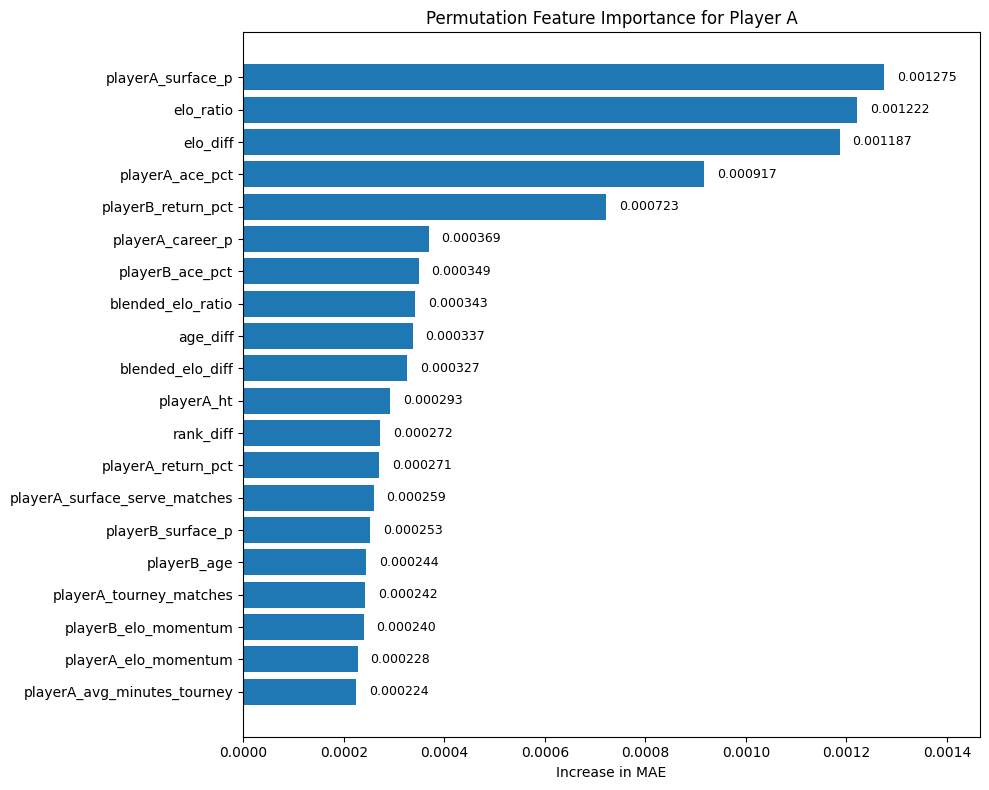

In [101]:
import matplotlib.pyplot as plt

# 1. Prepare data
top20 = pfi_dfA.head(20).iloc[::-1]  # Reverse for bottom-to-top plotting

plt.figure(figsize=(10, 8))

# 2. Create the bar chart
bars = plt.barh(top20["Feature"], top20["Permutation Importance"])

# 3. Add dynamic gap
# We set the label position at a small percentage of the max value
max_val = top20["Permutation Importance"].max()
offset = max_val * 0.02  # 2% gap from the end of the bar

# 4. Loop through bars to place text
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + offset,         # x-position (bar end + gap)
        bar.get_y() + bar.get_height()/2,  # y-position (center of bar)
        f'{width:.6f}',         # value formatted to 4 decimal places
        va='center',            # vertical alignment
        fontsize=9
    )

# 5. Styling
plt.xlabel("Increase in MAE")
plt.title("Permutation Feature Importance for Player A")
# Adjust x-limit to ensure labels don't get clipped by the right boundary
plt.xlim(0, max_val * 1.15) 

plt.tight_layout()
plt.show()


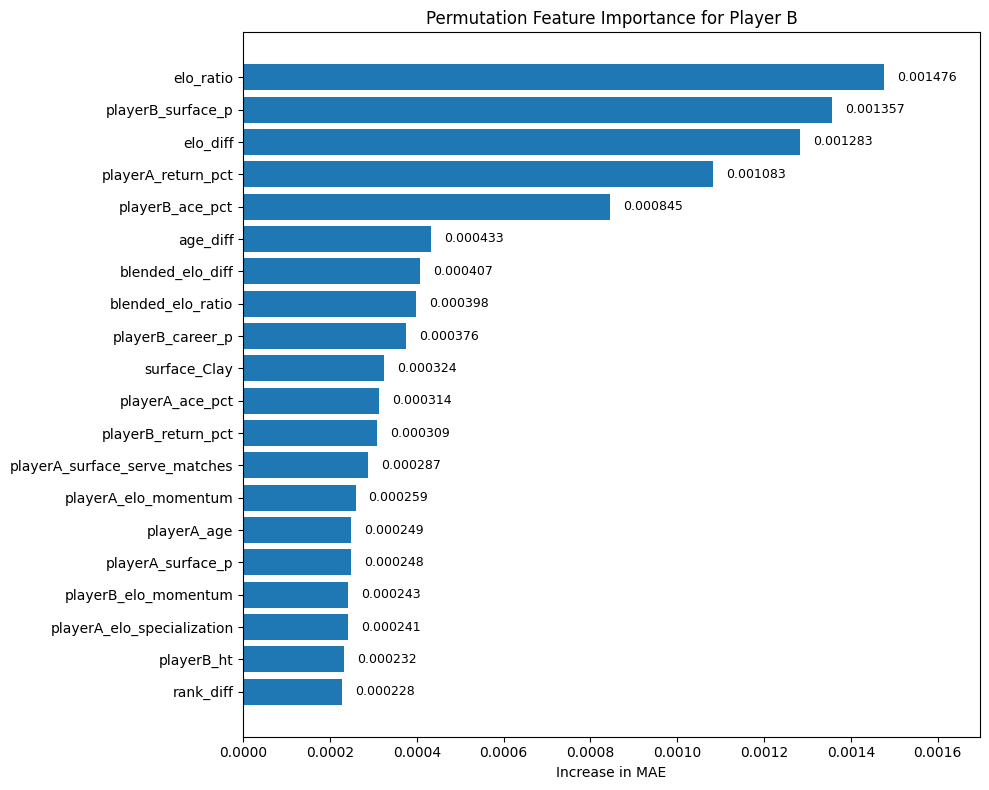

In [102]:
import matplotlib.pyplot as plt

# 1. Prepare data
top20 = pfi_dfB.head(20).iloc[::-1]  # Reverse for bottom-to-top plotting

plt.figure(figsize=(10, 8))

# 2. Create the bar chart
bars = plt.barh(top20["Feature"], top20["Permutation Importance"])

# 3. Add dynamic gap
# We set the label position at a small percentage of the max value
max_val = top20["Permutation Importance"].max()
offset = max_val * 0.02  # 2% gap from the end of the bar

# 4. Loop through bars to place text
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + offset,         # x-position (bar end + gap)
        bar.get_y() + bar.get_height()/2,  # y-position (center of bar)
        f'{width:.6f}',         # value formatted to 4 decimal places
        va='center',            # vertical alignment
        fontsize=9
    )

# 5. Styling
plt.xlabel("Increase in MAE")
plt.title("Permutation Feature Importance for Player B")
# Adjust x-limit to ensure labels don't get clipped by the right boundary
plt.xlim(0, max_val * 1.15) 

plt.tight_layout()
plt.show()


### Feature Group Importance


In [103]:
feature_groups = {
    "Ranking": ["playerA_rank_filled", "playerB_rank_filled", "playerA_is_unranked", "playerB_is_unranked", "playerA_rank_points_missing", 
                "playerB_rank_points_missing", "rank_diff", "rank_ratio", "playerA_points_filled", "playerB_points_filled", "playerA_top10", 
                "playerB_top10", "playerA_top32", "playerB_top32", "playerA_top64", "playerB_top64", "playerA_top100", "playerB_top100"], 

    "Elo": ["playerA_elo", "playerB_elo", "elo_diff", "playerA_surface_elo", "playerB_surface_elo", "surface_elo_diff", 
            'playerA_blended_elo', 'playerB_blended_elo', 'blended_elo_diff', 'elo_ratio', 'playerA_elo_momentum', 'playerB_elo_momentum', 
            'playerA_elo_volatility', 'playerB_elo_volatility', 'blended_elo_ratio', 'surface_elo_ratio'], 

    "Form": ["playerA_last10_wins", 
             "playerB_last10_wins", "playerA_last10_matches", "playerB_last10_matches", "playerA_last10_pct", "playerB_last10_pct", 
             "playerA_last25_wins", "playerB_last25_wins", "playerA_last25_matches", "playerB_last25_matches", "playerA_last25_pct", 
             "playerB_last25_pct", "playerA_surface10_wins", "playerB_surface10_wins", "playerA_surface10_matches", 
             "playerB_surface10_matches", "playerA_surface10_pct", "playerB_surface10_pct", "playerA_surface25_wins", 
             "playerB_surface25_wins", "playerA_surface25_matches", "playerB_surface25_matches", "playerA_surface25_pct", 
             "playerB_surface25_pct", "playerA_52w_wins", "playerB_52w_wins", "playerA_52w_matches", "playerB_52w_matches", 
             "playerA_52w_pct", "playerB_52w_pct", "playerA_career_matches", "playerB_career_matches", "playerA_surface_career_matches", 
             "playerB_surface_career_matches", "playerA_last10_losses", "playerB_last10_losses", "playerA_last25_losses", 
             "playerB_last25_losses", "playerA_surface10_losses", "playerB_surface10_losses", "playerA_surface25_losses", 
             "playerB_surface25_losses", "playerA_52w_losses", "playerB_52w_losses"], 

    "Matchup": ["playerA_h2h_wins", "playerB_h2h_wins", "h2h_total", "h2h_diff", "playerA_surface_h2h_wins", "playerB_surface_h2h_wins", 
                "surface_h2h_total", "surface_h2h_diff", "playerA_last5_h2h_wins", "playerB_last5_h2h_wins", "last5_h2h_total", 
                "last5_h2h_diff", "playerA_top20_wins", "playerB_top20_wins", "playerA_top20_losses", "playerB_top20_losses", 
                "playerA_top20_win_pct", "playerB_top20_win_pct", "playerA_hand_wins", "playerB_hand_wins", "playerA_hand_losses", 
                "playerB_hand_losses", "playerA_hand_win_pct", "playerB_hand_win_pct", 'playerA_top20_total', 'playerB_top20_total', 
                'playerA_hand_total', 'playerB_hand_total'], 

    "Fatigue":  ["playerA_matches_7d", "playerB_matches_7d", "playerA_matches_30d", "playerB_matches_30d", "playerA_wins_7d", 
                 "playerB_wins_7d", "playerA_wins_30d", "playerB_wins_30d", "playerA_winpct_7d", "playerB_winpct_7d", 
                 "playerA_winpct_30d", "playerB_winpct_30d", "playerA_minutes_tourney", "playerB_minutes_tourney", 
                 "playerA_avg_minutes_tourney", "playerB_avg_minutes_tourney", "playerA_losses_7d", "playerB_losses_7d", 
                 "playerA_losses_30d", "playerB_losses_30d"], 

    "Serve": ["playerA_ace_pct", "playerB_ace_pct", "playerA_df_pct", "playerB_df_pct", "playerA_1stIn_pct", "playerB_1stIn_pct", 
              "playerA_1stWon_pct", "playerB_1stWon_pct", "playerA_2ndWon_pct", "playerB_2ndWon_pct", "playerA_career_p", 
              "playerB_career_p", "playerA_serve_matches", "playerB_serve_matches", "playerA_matchup_p", "playerB_matchup_p", 
              "playerA_matchup_service_points", "playerB_matchup_service_points", "playerA_surface_p", "playerB_surface_p", 
              "playerA_surface_serve_matches", "playerB_surface_serve_matches"], 

    "Return": ["playerA_return_pct", "playerB_return_pct", "playerA_bp_convert_pct", "playerB_bp_convert_pct", "playerA_return_matches", 
               "playerB_return_matches"], 

    "Physical":  ['playerA_hand_A', 'playerA_hand_L', 'playerA_hand_R', 'playerA_hand_U', 'playerB_hand_A', 'playerB_hand_L', 
                  'playerB_hand_R','playerB_hand_U', "playerA_age", "playerB_age", "age_diff", "playerA_ht", "playerB_ht", "height_diff"],

    "Seed":  ["playerA_seeded", "playerB_seeded", "seed_diff", "seed_diff_missing"], 

    "Surface Specialization": ["playerA_win_rate_specialization", "playerB_win_rate_specialization", "playerA_elo_specialization", 
                               "playerB_elo_specialization", "playerA_serve_specialization", "playerB_serve_specialization"],

    "Experience": ["playerA_career_wins", "playerB_career_wins", "playerA_career_losses", "playerB_career_losses", "playerA_career_matches",
                    "playerA_career_pct", "playerB_career_matches", "playerA_surface_career_matches", "playerB_surface_career_matches",
                    "playerB_career_pct", "playerA_surface_career_wins", "playerB_surface_career_wins", "playerA_surface_career_losses", 
                    "playerB_surface_career_losses", "playerA_surface_career_pct", "playerB_surface_career_pct","playerA_level_wins", 
                    "playerB_level_wins", "playerA_level_losses", "playerB_level_losses", "playerA_level_win_pct", 
                   "playerA_tourney_matches", "playerB_tourney_matches", "playerA_level_matches", "playerB_level_matches", 
                   "playerB_level_win_pct"], 

    "Tournament Context": ["draw_size", "best_of", 'playerA_entry_ALT', 'playerA_entry_ITF', 'playerA_entry_LL', 
                           'playerA_entry_NONE', 'playerA_entry_OTHER', 'playerA_entry_PR', 'playerA_entry_Q', 'playerA_entry_SE', 
                           'playerA_entry_WC', 'playerB_entry_ALT', 'playerB_entry_ITF', 'playerB_entry_LL', 'playerB_entry_NONE', 
                           'playerB_entry_OTHER', 'playerB_entry_PR', 'playerB_entry_Q', 'playerB_entry_SE', 'playerB_entry_WC',
                           'round_BR', 'round_ER', 'round_F', 'round_Q1', 'round_Q2', 'round_Q3', 'round_QF', 'round_R128', 'round_R16', 
                           'round_R32', 'round_R64', 'round_RR', 'round_SF', 'tourney_level_A', 'tourney_level_C', 'tourney_level_D', 
                           'tourney_level_F', 'tourney_level_G', 'tourney_level_M', 'surface_Carpet', 'surface_Clay', 'surface_Grass', 
                           'surface_Hard',]
}


In [104]:
feature_importance_dictA = dict(zip(pfi_dfA["Feature"], pfi_dfA["Permutation Importance"]))
feature_importance_dictB = dict(zip(pfi_dfB["Feature"], pfi_dfB["Permutation Importance"]))


In [105]:
group_importanceA = {}
for group_name, features in feature_groups.items():
    total_importance = sum(feature_importance_dictA.get(feature, 0) for feature in features)
    group_importanceA[group_name] = total_importance


group_importanceB = {}
for group_name, features in feature_groups.items():
    total_importance = sum(feature_importance_dictB.get(feature, 0) for feature in features)
    group_importanceB[group_name] = total_importance


In [106]:
group_dfA = (
    pd.DataFrame({
        "Feature Group": group_importanceA.keys(),
        "Importance": group_importanceA.values()
    })
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

group_dfB = (
    pd.DataFrame({
        "Feature Group": group_importanceB.keys(),
        "Importance": group_importanceB.values()
    })
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)


In [107]:
group_dfA["Percentage"] = 100 * group_dfA["Importance"] / group_dfA["Importance"].sum()
group_dfB["Percentage"] = 100 * group_dfB["Importance"] / group_dfB["Importance"].sum()


In [108]:
PATH_CSV_A = "/content/drive/MyDrive/Projects/Tennis/v1/Permutation/v1_playerA_permutation_group_importance.csv"
group_dfA.to_csv(PATH_CSV_A, index= False)

PATH_CSV_B = "/content/drive/MyDrive/Projects/Tennis/v1/Permutation/v1_playerB_permutation_group_importance.csv"
group_dfB.to_csv(PATH_CSV_B, index= False)


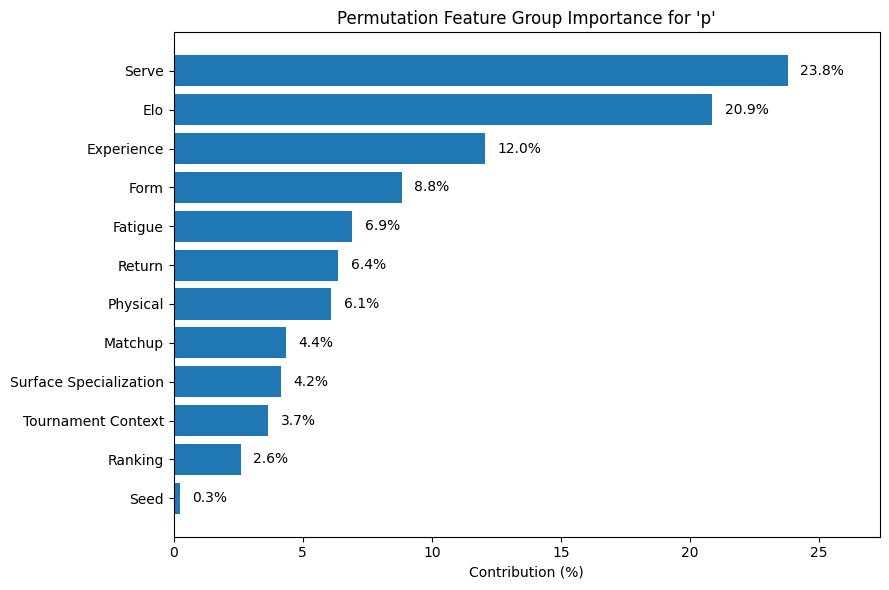

In [109]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

# Create the bars
bars = plt.barh(group_dfA["Feature Group"], group_dfA["Percentage"])

# Add labels
# We use a small offset relative to the max value for dynamic spacing
max_val = group_dfA["Percentage"].max()
offset = max_val * 0.02  # 2% of the max value as padding

for bar in bars:
    width = bar.get_width()
    plt.text(
        width + offset,              # x-position (bar edge + offset)
        bar.get_y() + bar.get_height() / 2, # y-position (center of bar)
        f'{width:.1f}%',            # text label (formatted to 1 decimal)
        va='center',                # vertical alignment
        fontsize=10
    )

plt.xlabel("Contribution (%)")
plt.title("Permutation Feature Group Importance for 'p'")

# Adjust x-limit slightly to ensure labels don't get cut off
plt.xlim(0, max_val * 1.15) 

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


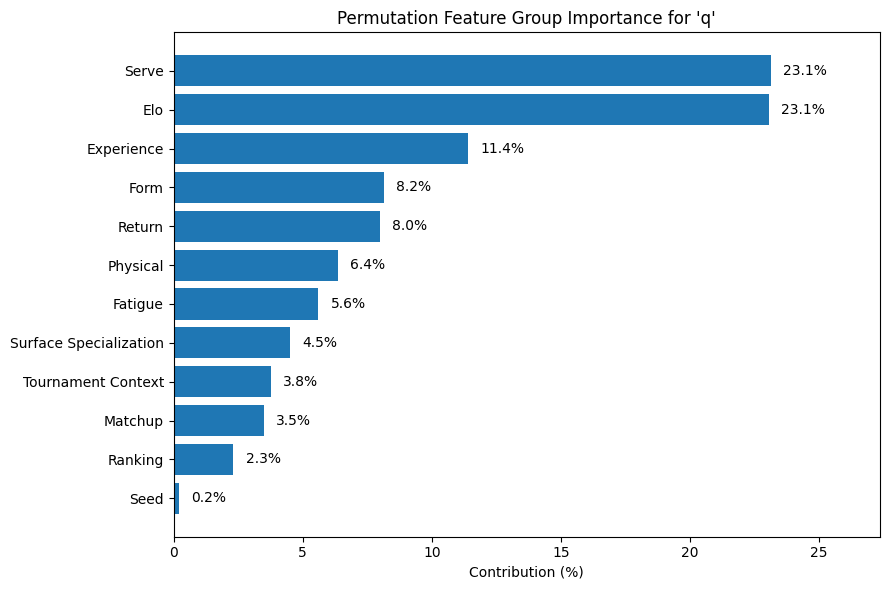

In [110]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

# Create the bars
bars = plt.barh(group_dfB["Feature Group"], group_dfB["Percentage"])

# Add labels
# We use a small offset relative to the max value for dynamic spacing
max_val = group_dfA["Percentage"].max()
offset = max_val * 0.02  # 2% of the max value as padding

for bar in bars:
    width = bar.get_width()
    plt.text(
        width + offset,              # x-position (bar edge + offset)
        bar.get_y() + bar.get_height() / 2, # y-position (center of bar)
        f'{width:.1f}%',            # text label (formatted to 1 decimal)
        va='center',                # vertical alignment
        fontsize=10
    )

plt.xlabel("Contribution (%)")
plt.title("Permutation Feature Group Importance for 'q'")

# Adjust x-limit slightly to ensure labels don't get cut off
plt.xlim(0, max_val * 1.15) 

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()
